# Gold vs Bitcoin: Time-Series Modelling, Forecasting and Diagnostics
**Mini-projet Séries Temporelles — TEK-UP — Option A (Finance)**

**Why these two series?** Bitcoin is often called "digital gold", while gold is the classic safe-haven asset. Testing whether they really move together (correlation, Granger causality, cointegration) is an interesting question, and their very different volatility (about 1% vs 4% per day) makes the comparison of models informative.

**Modelling question.** Do gold and Bitcoin share short-run or long-run dynamics, and which model forecasts their log price best at horizons h = 1, 5 and 10 days, *compared with a naive "tomorrow = today" benchmark*?

**Install once:** `pip install yfinance statsmodels arch pmdarima tensorflow prophet`

| Cahier section | Where |
|---|---|
| 1 Data | Section 1 |
| 2 EDA | Section 2 |
| 3.1 ARIMA / 3.2 VAR + cointegration / 3.3 GARCH | Section 3 |
| 4.1 LSTM/GRU + walk-forward / 4.3 Prophet + rolling correlation | Sections 4 and 5 |
| 6 Forecast + Diebold-Mariano | Section 5 |
| 5 LLM | Section 6 (placed after the results, because the LLM prompts use them) |
| 8.4 Critical discussion | Section 7 |

**Rule used everywhere:** every conclusion sentence is *generated from the computed p-values and metrics*, so the text cannot disagree with the numbers.

In [28]:
# WHY: fix seeds and folders so that every run gives the same results.
import os, random, warnings, copy, time, logging
from collections import defaultdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import yfinance as yf

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); os.environ["PYTHONHASHSEED"] = str(SEED)

# QUICK=1 shrinks the neural-network grid/epochs. Only used to check quickly that the notebook runs.
QUICK = os.environ.get("QUICK", "0") == "1"

ROOT = Path("..").resolve()

DATA_DIR = ROOT / "data"
FIG_DIR  = ROOT / "figures"
LLM_DIR  = ROOT / "llm"

for d in (DATA_DIR, FIG_DIR, LLM_DIR):
    d.mkdir(exist_ok=True)

print("Project root :", ROOT)
print("Data folder  :", DATA_DIR)
print("Figures folder:", FIG_DIR)
print("LLM folder   :", LLM_DIR)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
cost = defaultdict(float)     # compute time per model (seconds), used in the final comparison table

import statsmodels, arch, pmdarima, tensorflow as tf, prophet
print("Versions:", {m.__name__: m.__version__ for m in (np, pd, statsmodels, arch, pmdarima, tf, prophet)})
tf.keras.utils.set_random_seed(SEED)
tf.get_logger().setLevel("ERROR")      # hide harmless TensorFlow retracing warnings

Project root : C:\Users\bilel\Downloads\gold vs btc\gold vs btc
Data folder  : C:\Users\bilel\Downloads\gold vs btc\gold vs btc\data
Figures folder: C:\Users\bilel\Downloads\gold vs btc\gold vs btc\figures
LLM folder   : C:\Users\bilel\Downloads\gold vs btc\gold vs btc\llm
Versions: {'numpy': '2.5.3', 'pandas': '3.0.6', 'statsmodels': '0.15.0', 'arch': '8.0.0', 'pmdarima': '2.1.1', 'tensorflow': '2.22.0-rc0', 'prophet': '1.5.0'}


## 1. Data

- **Source:** Yahoo Finance via `yfinance`. **Gold** = `GLD` (SPDR Gold Shares ETF, USD; an ETF share price, not the spot price per ounce). **Bitcoin** = `BTC-USD`.
- **Prices used:** `Close` (not adjusted). GLD and BTC pay no dividends, so no dividend adjustment is involved.
- **Period:** 2019-01-01 to **2026-10-14 (fixed end date)**. The raw download is cached in `data/aligned_prices_returns.csv`, so the data never changes between runs.
- **Calendar:** Bitcoin trades 7 days a week, GLD only on business days. I keep GLD trading days only (no invented weekend gold prices). **Limit:** a Monday Bitcoin return covers Friday → Monday (3 days), so Monday returns are slightly larger on average.
- **Frequency:** business days with holidays missing, so the index has no regular frequency; statsmodels models use the integer position.
- **Derived variable:** daily log return $r_t=\log P_t-\log P_{t-1}$.
- **Split:** chronological 90 % train / 10 % test, no shuffling.

In [29]:
# WHY: load the cached prices (or download them once with a FIXED end date), build log prices and log returns, split 90/10.
START, END = "2019-01-01", "2026-10-14"
CSV = DATA_DIR / "aligned_prices_returns.csv"

if CSV.exists():
    prices = pd.read_csv(CSV, parse_dates=["date"], index_col="date")
    print("Loaded cached data:", CSV)
else:
    raw = yf.download(["GLD", "BTC-USD"], start=START, end=END, auto_adjust=False, progress=False)
    close = raw["Close"].rename(columns={"GLD": "gold_price", "BTC-USD": "btc_price"})
    prices = close.dropna(subset=["gold_price"])          # keep GLD trading days
    prices.to_csv(CSV, index_label="date")
    print("Downloaded and cached:", CSV)

df = prices[["gold_price", "btc_price"]].dropna().loc[START:END].copy()
for a in ("gold", "btc"):
    df[f"{a}_logprice"] = np.log(df[f"{a}_price"])
    df[f"{a}_return"] = df[f"{a}_logprice"].diff()
df = df.dropna()

n = len(df)
split_idx = int(n * 0.90)
train, test = df.iloc[:split_idx], df.iloc[split_idx:]
print(f"Observations: {n} | train: {len(train)} ({train.index[0].date()} -> {train.index[-1].date()}) "
      f"| test: {len(test)} ({test.index[0].date()} -> {test.index[-1].date()})")
display(df.head(3)); display(df.tail(3))

Loaded cached data: C:\Users\bilel\Downloads\gold vs btc\gold vs btc\data\aligned_prices_returns.csv
Observations: 1955 | train: 1759 (2019-01-03 -> 2025-12-31) | test: 196 (2026-01-02 -> 2026-10-13)


,gold_price,btc_price,gold_logprice,gold_return,btc_logprice,btc_return
date,,,,,,
2019-01-03,122.43,3836.7,4.8075,0.0090253,8.2524,-0.027422
2019-01-04,121.44,3857.7,4.7994,-0.0081191,8.2578,0.0054523
2019-01-07,121.86,4025.2,4.8029,0.0034525,8.3003,0.042511


,gold_price,btc_price,gold_logprice,gold_return,btc_logprice,btc_return
date,,,,,,
2026-10-09,384.58,82546,5.9522,0.015619,11.321,0.010595
2026-10-12,382.15,81763,5.9458,-0.0063386,11.312,-0.0095401
2026-10-13,381.67,83095,5.9446,-0.0012568,11.328,0.016167


## 2. Exploratory analysis

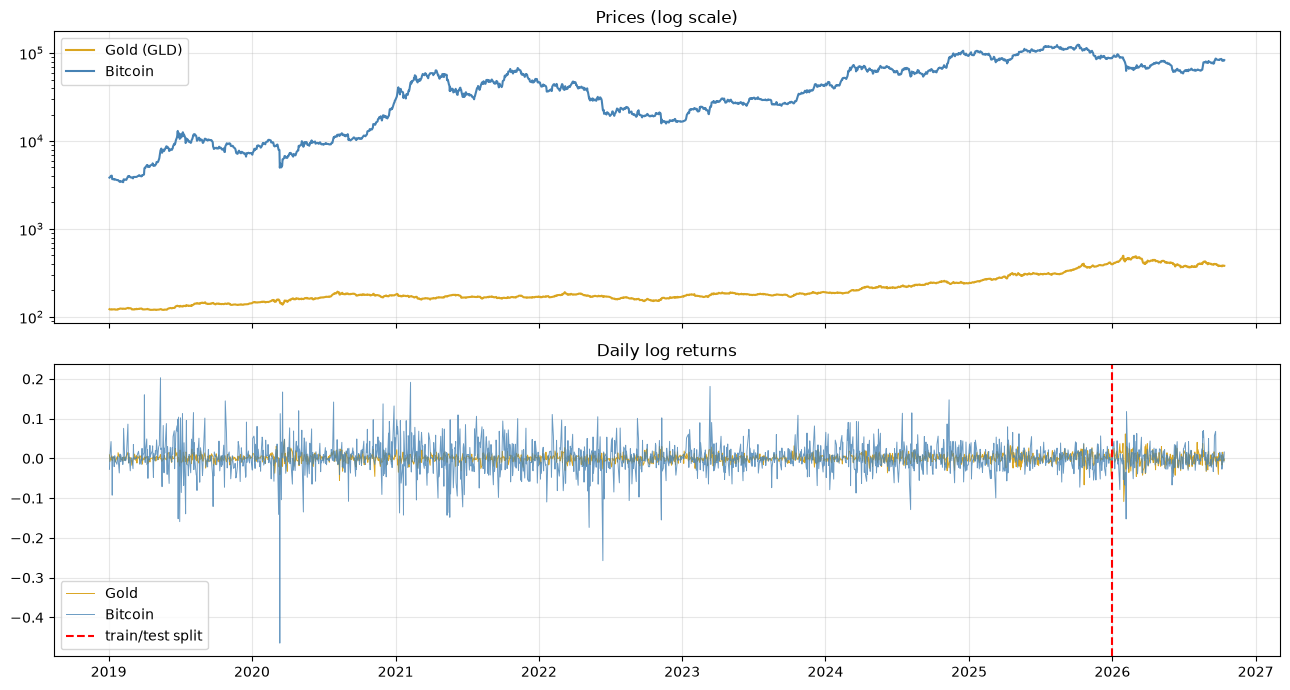

In [3]:
# WHY: look at trend, scale difference and volatility regimes before choosing any model.
fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ax[0].plot(df.index, df["gold_price"], label="Gold (GLD)", color="goldenrod")
ax[0].plot(df.index, df["btc_price"], label="Bitcoin", color="steelblue")
ax[0].set_yscale("log"); ax[0].set_title("Prices (log scale)"); ax[0].legend()
ax[1].plot(df.index, df["gold_return"], label="Gold", color="goldenrod", lw=0.7)
ax[1].plot(df.index, df["btc_return"], label="Bitcoin", color="steelblue", lw=0.7, alpha=0.8)
ax[1].axvline(train.index[-1], color="red", ls="--", label="train/test split")
ax[1].set_title("Daily log returns"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "01_prices_returns.png", dpi=120); plt.show()

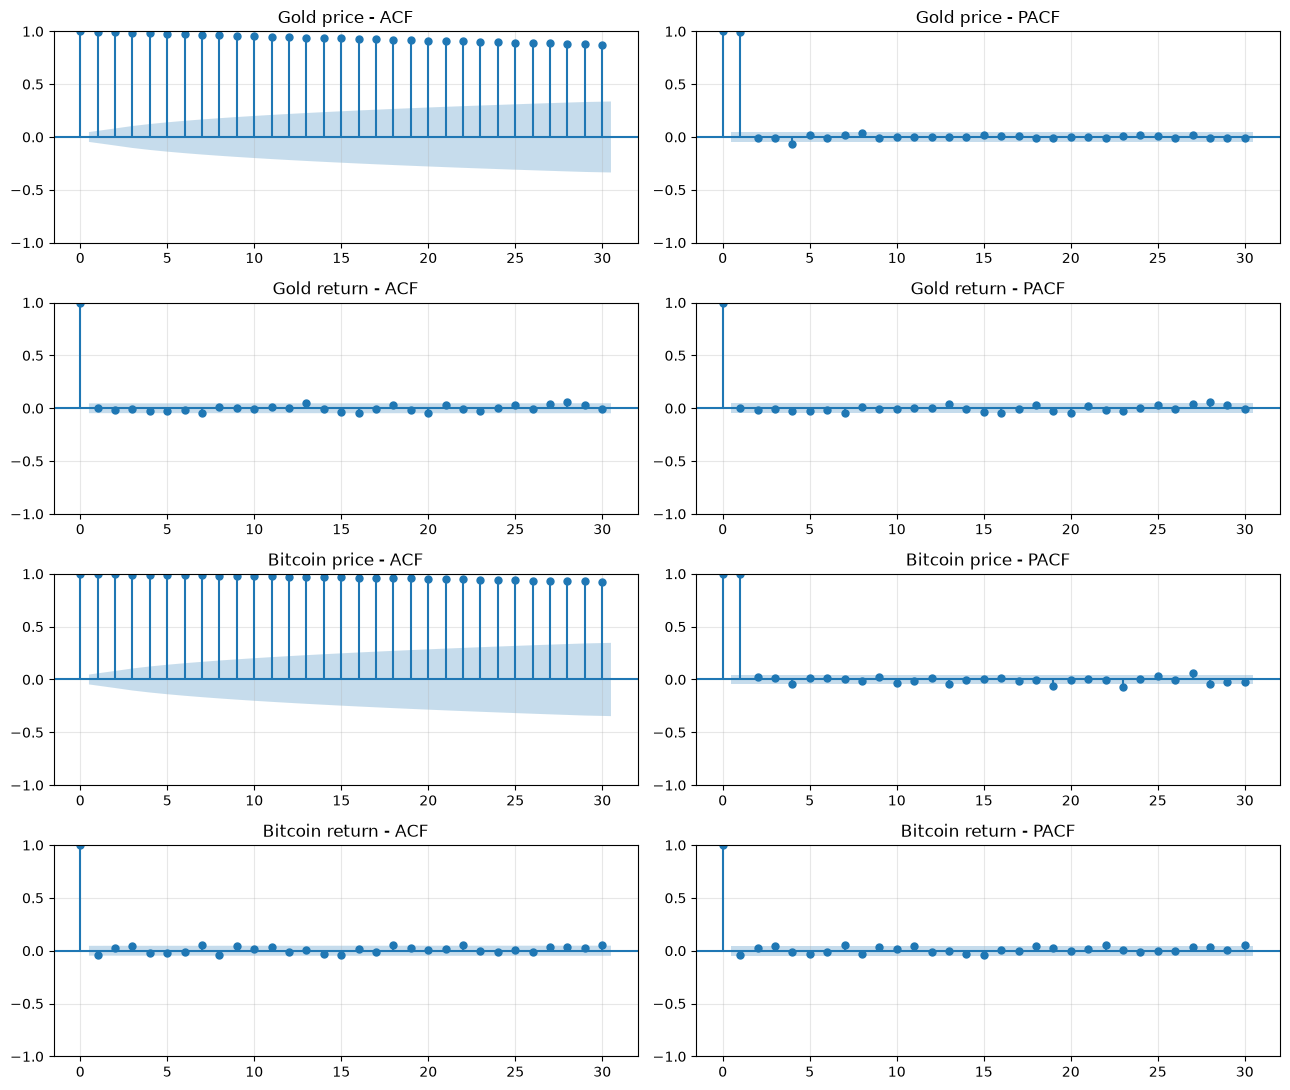

95% band = +/-0.047. Number of significant ACF lags (1..30) of the RETURNS:
  Gold: 1/30 lags outside the band, lag-1 autocorrelation = 0.006
  Bitcoin: 5/30 lags outside the band, lag-1 autocorrelation = -0.040


In [4]:
# WHY: ACF/PACF of the raw series and of the differenced series (returns) show how much differencing is needed and which ARMA terms might exist.
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

fig, axes = plt.subplots(4, 2, figsize=(13, 11))
for i, (col, title) in enumerate([("gold_price", "Gold price"), ("gold_return", "Gold return"),
                                  ("btc_price", "Bitcoin price"), ("btc_return", "Bitcoin return")]):
    plot_acf(train[col], lags=30, ax=axes[i, 0], title=f"{title} - ACF")
    plot_pacf(train[col], lags=30, ax=axes[i, 1], method="ywm", title=f"{title} - PACF")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_acf_pacf.png", dpi=120); plt.show()

band = 1.96 / np.sqrt(len(train))
print(f"95% band = +/-{band:.3f}. Number of significant ACF lags (1..30) of the RETURNS:")
from statsmodels.tsa.stattools import acf
for col, name in [("gold_return", "Gold"), ("btc_return", "Bitcoin")]:
    ac = acf(train[col], nlags=30)
    print(f"  {name}: {int((np.abs(ac[1:]) > band).sum())}/30 lags outside the band, lag-1 autocorrelation = {ac[1]:.3f}")

**Interpretation of ACF/PACF (written):**
- **Raw prices (gold and Bitcoin):** the ACF decays very slowly over 30 lags and the PACF has one huge spike at lag 1 (close to 1), then nothing. This is the signature of a non-stationary, integrated process, so differencing (d = 1) is needed.
- **Returns (first difference):** unlike prices, there is no persistent pattern. The counts printed above show how many lags cross the 95 % band: only a few isolated lags, with small values, mean there is little linear structure left to model. This points to ARIMA(0,1,0)-like models (a random walk, possibly with drift) for log prices, and any ARMA terms chosen by `auto_arima` should add very little. The manual order is compared with `auto_arima` in 3.1.
- **Squared returns** (next cell) are used to check volatility clustering, which is *not* visible in the ACF of returns themselves.

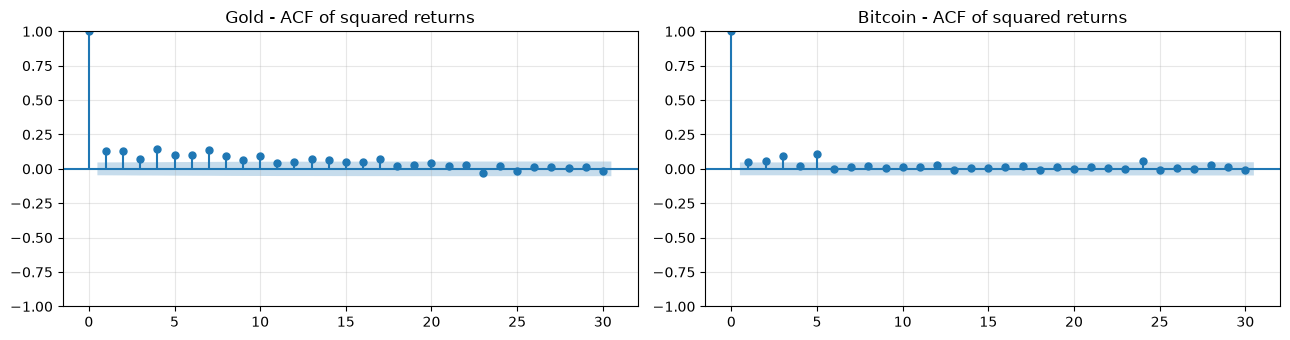

Gold: Ljung-Box(10) on returns p=0.7455 -> no significant linear autocorrelation; on squared returns p=1.28e-40 -> volatility clustering present
Bitcoin: Ljung-Box(10) on returns p=0.0178 -> linear autocorrelation present; on squared returns p=1.72e-06 -> volatility clustering present


In [5]:
# WHY: the ACF of squared returns detects volatility clustering (which the ACF of returns cannot see). Ljung-Box gives a formal test.
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for ax_, (col, name) in zip(axes, [("gold_return", "Gold"), ("btc_return", "Bitcoin")]):
    plot_acf(train[col] ** 2, lags=30, ax=ax_, title=f"{name} - ACF of squared returns")
plt.tight_layout(); plt.savefig(FIG_DIR / "03_acf_squared_returns.png", dpi=120); plt.show()

for col, name in [("gold_return", "Gold"), ("btc_return", "Bitcoin")]:
    p_r  = acorr_ljungbox(train[col], lags=[10]).iloc[0]["lb_pvalue"]
    p_r2 = acorr_ljungbox(train[col] ** 2, lags=[10]).iloc[0]["lb_pvalue"]
    print(f"{name}: Ljung-Box(10) on returns p={p_r:.4f} -> "
          f"{'linear autocorrelation present' if p_r < 0.05 else 'no significant linear autocorrelation'}; "
          f"on squared returns p={p_r2:.2e} -> "
          f"{'volatility clustering present' if p_r2 < 0.05 else 'no evidence of volatility clustering'}")

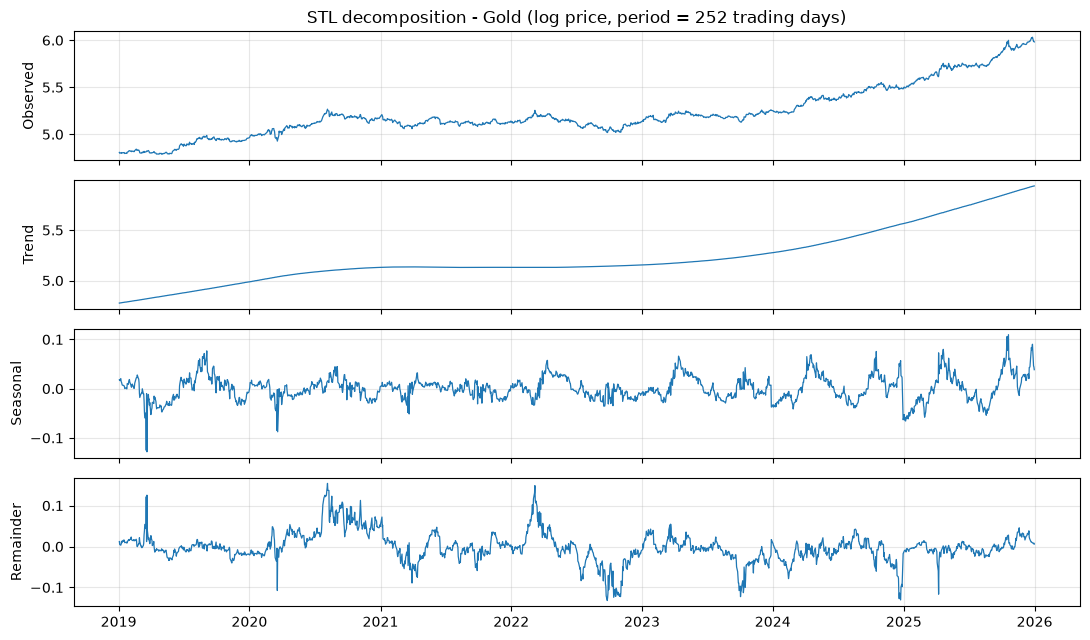

Gold: strength of trend = 0.98, strength of seasonality = 0.30


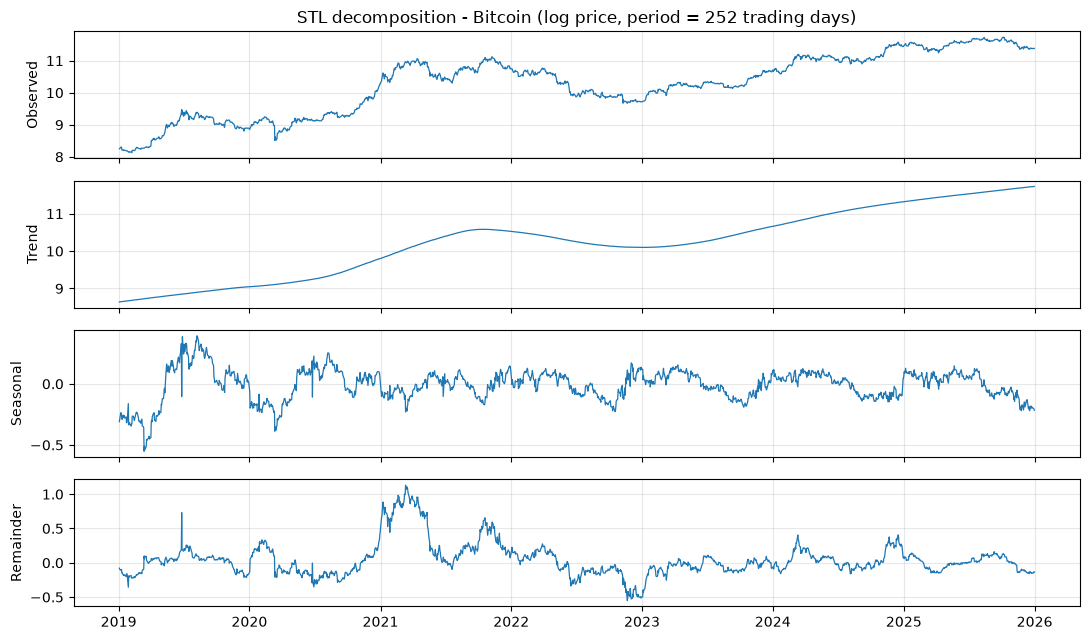

Bitcoin: strength of trend = 0.93, strength of seasonality = 0.17


In [6]:
# WHY: STL on LOG prices (an additive model on logs = multiplicative on prices) separates trend, yearly seasonality (252 days) and remainder.
from statsmodels.tsa.seasonal import STL

for col, name in [("gold_logprice", "Gold"), ("btc_logprice", "Bitcoin")]:
    stl = STL(train[col].values, period=252, robust=True).fit()
    fig, ax = plt.subplots(4, 1, figsize=(11, 6.5), sharex=True)
    for a_, s_, lab in zip(ax, [stl.observed, stl.trend, stl.seasonal, stl.resid], ["Observed", "Trend", "Seasonal", "Remainder"]):
        a_.plot(train.index, s_, lw=0.9); a_.set_ylabel(lab)
    ax[0].set_title(f"STL decomposition - {name} (log price, period = 252 trading days)")
    plt.tight_layout(); plt.savefig(FIG_DIR / f"04_stl_{name.lower()}.png", dpi=120); plt.show()
    # strength of trend / seasonality (Hyndman): 0 = none, 1 = very strong
    Ft = max(0, 1 - np.var(stl.resid) / np.var(stl.trend + stl.resid))
    Fs = max(0, 1 - np.var(stl.resid) / np.var(stl.seasonal + stl.resid))
    print(f"{name}: strength of trend = {Ft:.2f}, strength of seasonality = {Fs:.2f}")

**STL interpretation:** the trend component carries almost all the variation of both log prices (strength 0.98 for gold, 0.93 for Bitcoin). The yearly seasonal component is weak (strength about 0.30 for gold and 0.17 for Bitcoin; see the values printed above), so it is not a strong enough pattern to justify seasonal SARIMA terms. This is only a rough check (period 252 on about 7 years of data). The remainder contains the large short-term shocks, which is where the volatility clustering lives.

In [7]:
# WHY: detect outliers in returns with the IQR rule and decide what to do with them.
rows = []
for col, name in [("gold_return", "Gold"), ("btc_return", "Bitcoin")]:
    s = train[col]
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    mask = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    rows.append({"Asset": name, "IQR outliers": int(mask.sum()), "share (%)": round(100 * mask.mean(), 1),
                 "largest gain": f"{s.max():.3f} on {s.idxmax().date()}",
                 "largest loss": f"{s.min():.3f} on {s.idxmin().date()}"})
display(pd.DataFrame(rows))

,Asset,IQR outliers,share (%),largest gain,largest loss
0,Gold,71,4.0,0.047 on 2020-03-24,-0.066 on 2025-10-21
1,Bitcoin,117,6.7,0.203 on 2019-05-13,-0.465 on 2020-03-12


**Outlier treatment: all outliers are kept.** They are real market events (e.g. the March 2020 crash), not data errors, and they carry exactly the information that GARCH needs to model volatility. Removing them would hide the heavy tails. The consequence is that residuals will not be normal, and this is handled by using a Student-t distribution in the GARCH model.

In [8]:
# WHY: ADF (H0 = unit root) and KPSS (H0 = stationary) have opposite null hypotheses, so using both makes the conclusion safer.
from statsmodels.tsa.stattools import adfuller
from arch.unitroot import KPSS

rows = []
for col, label in [("gold_price", "Gold price"), ("gold_logprice", "Gold log price"), ("gold_return", "Gold return"),
                   ("btc_price", "Bitcoin price"), ("btc_logprice", "Bitcoin log price"), ("btc_return", "Bitcoin return")]:
    s = train[col]
    adf_p = adfuller(s, autolag="AIC")[1]
    kpss_p = KPSS(s, trend="c").pvalue
    verdict = ("Stationary" if (adf_p < 0.05 and kpss_p >= 0.05) else
               "Non-stationary" if (adf_p >= 0.05 and kpss_p < 0.05) else "Inconclusive (tests disagree)")
    rows.append({"Series": label, "ADF p-value": round(adf_p, 4), "KPSS p-value": round(kpss_p, 4), "Conclusion": verdict})
stat_df = pd.DataFrame(rows)
display(stat_df)

lvl_ns = stat_df[stat_df.Series.str.contains("log price")]["Conclusion"].eq("Non-stationary").all()
ret_st = stat_df[stat_df.Series.str.contains("return")]["Conclusion"].eq("Stationary").all()
print("Differencing order:", "d = 1 (log prices are non-stationary, their first difference = returns is stationary)."
      if (lvl_ns and ret_st) else "Check the table: the tests do not give a clean d = 1 conclusion.")
print("Note: the tests are run on prices, log prices and returns. ARIMA below is fitted on LOG prices, "
      "so the 'Log price' rows are the ones that justify d.")

,Series,ADF p-value,KPSS p-value,Conclusion
0,Gold price,1.0000,0.0001,Non-stationary
1,Gold log price,0.9944,0.0001,Non-stationary
2,Gold return,0.0000,0.0935,Stationary
3,Bitcoin price,0.6330,0.0001,Non-stationary
4,Bitcoin log price,0.3283,0.0001,Non-stationary
5,Bitcoin return,0.0000,0.3843,Stationary


Differencing order: d = 1 (log prices are non-stationary, their first difference = returns is stationary).
Note: the tests are run on prices, log prices and returns. ARIMA below is fitted on LOG prices, so the 'Log price' rows are the ones that justify d.


## 3. Classical models

### 3.1 ARIMA and residual diagnostics
Two ways to choose the order, as the cahier asks: **(a) manual**, from the ACF/PACF above (returns show almost no structure, so ARIMA(0,1,0) with drift), and **(b) automatic** with `auto_arima` (AIC). Both are fitted on **log prices** of the training set and compared by AIC.

**Important detail:** with d = 1, the first value returned by `model.resid()` is not a real residual (it is the log price itself, about 5 to 9, instead of an error of about 0.01 to 0.04). It is dropped before any test; otherwise this single value ruins Ljung-Box and Jarque-Bera.

In [9]:
# WHY: fit manual and automatic ARIMA on log prices, keep the lower AIC, then run the 3 required residual tests on VALID residuals.
from pmdarima import auto_arima, ARIMA
from scipy.stats import jarque_bera
from statsmodels.stats.diagnostic import het_arch

arima_models, cmp_rows, diag_rows = {}, [], []
for col, name in [("gold_logprice", "Gold"), ("btc_logprice", "Bitcoin")]:
    s = train[col].values
    t0 = time.perf_counter()
    auto = auto_arima(s, seasonal=False, stepwise=True, suppress_warnings=True, error_action="ignore",
                      max_p=5, max_q=5, information_criterion="aic")
    manual = ARIMA(order=(0, 1, 0), with_intercept=True).fit(s)
    cost["ARIMA"] += time.perf_counter() - t0
    final = auto if auto.aic() <= manual.aic() else manual
    arima_models[name] = final
    cmp_rows += [{"Asset": name, "Method": "Manual (ACF/PACF)", "Order": str(manual.order), "AIC": round(manual.aic(), 1), "BIC": round(manual.bic(), 1)},
                 {"Asset": name, "Method": "auto_arima", "Order": str(auto.order), "AIC": round(auto.aic(), 1), "BIC": round(auto.bic(), 1)}]

    resid = pd.Series(final.resid()).iloc[final.order[1]:]        # drop the first d values (not real residuals)
    lb = acorr_ljungbox(resid, lags=[10]).iloc[0]
    jb_stat, jb_p = jarque_bera(resid)
    arch_stat, arch_p, _, _ = het_arch(resid, nlags=10)
    diag_rows += [
        {"Asset": name, "Final order": str(final.order), "Residual std": round(resid.std(), 4), "Test": "Ljung-Box (10)", "Statistic": round(lb["lb_stat"], 3), "p-value": lb["lb_pvalue"]},
        {"Asset": name, "Final order": str(final.order), "Residual std": round(resid.std(), 4), "Test": "Jarque-Bera", "Statistic": round(jb_stat, 1), "p-value": jb_p},
        {"Asset": name, "Final order": str(final.order), "Residual std": round(resid.std(), 4), "Test": "ARCH-LM (10)", "Statistic": round(arch_stat, 3), "p-value": arch_p}]

display(pd.DataFrame(cmp_rows))
arima_diag = pd.DataFrame(diag_rows)
arima_diag["Reading"] = arima_diag.apply(lambda r: {
    "Ljung-Box (10)": "no remaining autocorrelation" if r["p-value"] > 0.05 else "autocorrelation remains",
    "Jarque-Bera": "normality not rejected" if r["p-value"] > 0.05 else "normality rejected (fat tails)",
    "ARCH-LM (10)": "no ARCH effect" if r["p-value"] > 0.05 else "ARCH effect present"}[r["Test"]], axis=1)
arima_diag["p-value"] = arima_diag["p-value"].map(lambda v: f"{v:.3g}")
display(arima_diag)
arima_diag.to_csv(DATA_DIR / "arima_diagnostics.csv", index=False)
print("Sanity check: the residual std should be small (about 0.01-0.04), as shown in the table.")

,Asset,Method,Order,AIC,BIC
0,Gold,Manual (ACF/PACF),"(0, 1, 0)",-11221.5,-11210.6
1,Gold,auto_arima,"(0, 1, 0)",-11221.5,-11210.6
2,Bitcoin,Manual (ACF/PACF),"(0, 1, 0)",-6341.9,-6330.9
3,Bitcoin,auto_arima,"(2, 1, 2)",-6345.3,-6312.5


,Asset,Final order,Residual std,Test,Statistic,p-value,Reading
0,Gold,"(0, 1, 0)",0.0099,Ljung-Box (10),6.813,0.743,no remaining autocorrelation
1,Gold,"(0, 1, 0)",0.0099,Jarque-Bera,847.400,9.61e-185,normality rejected (fat tails)
2,Gold,"(0, 1, 0)",0.0099,ARCH-LM (10),110.025,5.27e-19,ARCH effect present
3,Bitcoin,"(2, 1, 2)",0.0397,Ljung-Box (10),9.994,0.441,no remaining autocorrelation
4,Bitcoin,"(2, 1, 2)",0.0397,Jarque-Bera,13697.100,0,normality rejected (fat tails)
5,Bitcoin,"(2, 1, 2)",0.0397,ARCH-LM (10),33.521,0.000223,ARCH effect present


Sanity check: the residual std should be small (about 0.01-0.04), as shown in the table.


In [10]:
# WHY: turn the test results into sentences automatically, so the text always matches the numbers.
for name in ("Gold", "Bitcoin"):
    sub = arima_diag[arima_diag.Asset == name].set_index("Test")["Reading"]
    print(f"{name} ARIMA{arima_models[name].order}: Ljung-Box -> {sub['Ljung-Box (10)']}; "
          f"Jarque-Bera -> {sub['Jarque-Bera']}; ARCH-LM -> {sub['ARCH-LM (10)']}.")
print("\nThese tests give evidence (not a proof) about the residuals. Where ARCH effects are present, the ARIMA mean model is fine "
      "but its constant-variance assumption is not, which motivates the GARCH model of section 3.3.")

Gold ARIMA(0, 1, 0): Ljung-Box -> no remaining autocorrelation; Jarque-Bera -> normality rejected (fat tails); ARCH-LM -> ARCH effect present.
Bitcoin ARIMA(2, 1, 2): Ljung-Box -> no remaining autocorrelation; Jarque-Bera -> normality rejected (fat tails); ARCH-LM -> ARCH effect present.

These tests give evidence (not a proof) about the residuals. Where ARCH effects are present, the ARIMA mean model is fine but its constant-variance assumption is not, which motivates the GARCH model of section 3.3.


**Choice of order for Bitcoin:** `auto_arima` selected ARIMA(2,1,2) (lowest AIC), but the AIC gain over the manual ARIMA(0,1,0) is only 3.4 points, and BIC (which penalizes complexity more) prefers (0,1,0) by about 18 points. Both models leave no autocorrelation in the residuals (Ljung-Box p > 0.05), so the simpler model is just as adequate. The notebook keeps the AIC rule, but the forecasting results below show that the extra terms do not help.

### 3.2 VAR, Granger causality and cointegration
- **VAR** on the two stationary return series, lag chosen by AIC.
- **Granger causality** inside the VAR (H0: the other asset does *not* help predict this one).
- **Engle-Granger cointegration** on log prices (H0: no cointegration). A VECM is only estimated if cointegration is found.

In [11]:
# WHY: model the interaction between the two assets; conclusions are generated from the p-values.
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import coint

rets = train[["gold_return", "btc_return"]]
sel = VAR(rets).select_order(maxlags=10)
var_lag = max(int(sel.aic), 1)
var_model = VAR(rets).fit(var_lag)
print(f"VAR lag selected by AIC: {var_lag}")

gc = {"Gold -> Bitcoin": var_model.test_causality("btc_return", ["gold_return"], kind="f"),
      "Bitcoin -> Gold": var_model.test_causality("gold_return", ["btc_return"], kind="f")}
granger_df = pd.DataFrame([{"Direction": k, "F-stat": round(v.test_statistic, 3), "p-value": round(v.pvalue, 4),
                            "Conclusion": "Granger-causes (p < 0.05)" if v.pvalue < 0.05 else "No Granger causality (p >= 0.05)"}
                           for k, v in gc.items()])
display(granger_df)

coint_stat, coint_p, _ = coint(train["gold_logprice"], train["btc_logprice"], trend="c")
coint_df = pd.DataFrame([{"Test": "Engle-Granger (log prices)", "Statistic": round(coint_stat, 3), "p-value": round(coint_p, 4),
                          "Conclusion": "Cointegrated" if coint_p < 0.05 else f"Not cointegrated (p = {coint_p:.4f} >= 0.05)"}])
display(coint_df)

if coint_p < 0.05:
    from statsmodels.tsa.vector_ar.vecm import VECM
    vecm = VECM(train[["gold_logprice", "btc_logprice"]], k_ar_diff=max(var_lag - 1, 1), coint_rank=1, deterministic="co").fit()
    print("VECM error-correction coefficients alpha (speed of return to equilibrium):", vecm.alpha.ravel())
else:
    print("No cointegration -> a VECM would be spurious and is not estimated. The VAR on returns is the right multivariate model.")

VAR lag selected by AIC: 1


C:\Users\bilel\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\bilel\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


,Direction,F-stat,p-value,Conclusion
0,Gold -> Bitcoin,0.119,0.7298,No Granger causality (p >= 0.05)
1,Bitcoin -> Gold,0.006,0.9365,No Granger causality (p >= 0.05)


,Test,Statistic,p-value,Conclusion
0,Engle-Granger (log prices),-0.266,0.9774,Not cointegrated (p = 0.9774 >= 0.05)


No cointegration -> a VECM would be spurious and is not estimated. The VAR on returns is the right multivariate model.


### 3.3 Conditional volatility: GARCH(1,1)
The ARIMA residual test in 3.1 checks for ARCH effects (typical for financial returns), so I fit GARCH(1,1) on returns (scaled by 100 for the optimizer) with a **normal** and a **Student-t** distribution, compare them by AIC, and check that the standardized residuals no longer show ARCH effects.

,Asset,Distribution,alpha,beta,Persistence,AIC,ARCH-LM p (std. resid),Std. residuals
0,Gold,normal,0.105,0.835,0.940,4792.0,0.7986,no ARCH left
1,Gold,t,0.072,0.891,0.963,4715.8,0.7495,no ARCH left
2,Bitcoin,normal,0.136,0.782,0.918,9681.0,0.1369,no ARCH left
3,Bitcoin,t,0.067,0.929,0.996,9274.3,0.0744,no ARCH left


Gold: lowest AIC with the 't' distribution.
Bitcoin: lowest AIC with the 't' distribution.


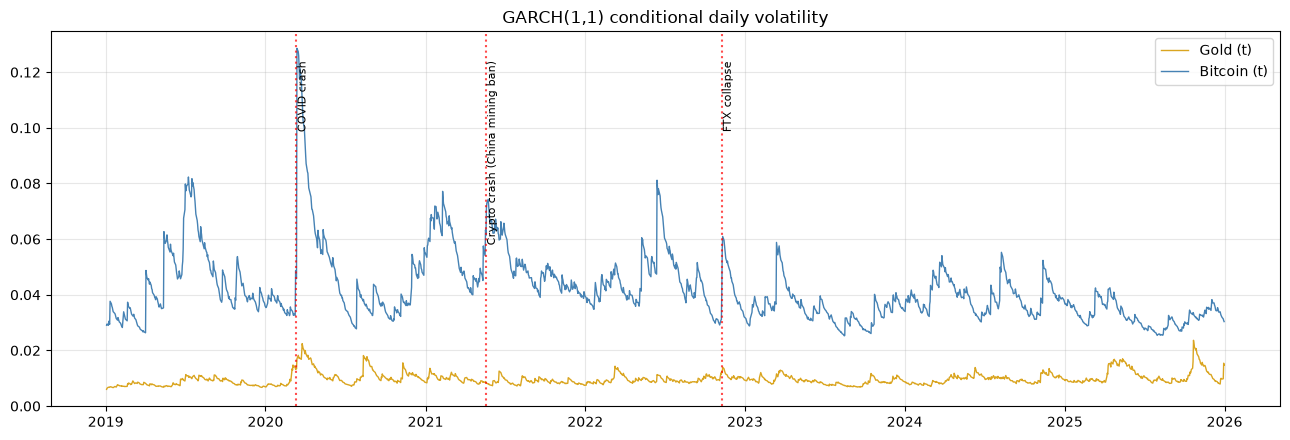

In [12]:
# WHY: GARCH(1,1) with normal vs Student-t errors; check standardized residuals with ARCH-LM; plot volatility against real events.
from arch import arch_model

garch_best, rows = {}, []
for col, name in [("gold_return", "Gold"), ("btc_return", "Bitcoin")]:
    fits = {}
    for dist in ("normal", "t"):
        res = arch_model(train[col] * 100, mean="Constant", vol="GARCH", p=1, q=1, dist=dist).fit(disp="off")
        fits[dist] = res
        lm_p = het_arch(res.std_resid.dropna(), nlags=10)[1]
        rows.append({"Asset": name, "Distribution": dist, "alpha": round(res.params["alpha[1]"], 3), "beta": round(res.params["beta[1]"], 3),
                     "Persistence": round(res.params["alpha[1]"] + res.params["beta[1]"], 3),
                     "AIC": round(res.aic, 1), "ARCH-LM p (std. resid)": round(lm_p, 4),
                     "Std. residuals": "no ARCH left" if lm_p > 0.05 else "ARCH remains"})
    best = min(fits, key=lambda d: fits[d].aic)
    garch_best[name] = (fits[best], best)
garch_df = pd.DataFrame(rows)
display(garch_df)
for name, (res, dist) in garch_best.items():
    print(f"{name}: lowest AIC with the '{dist}' distribution.")

events = {"2020-03-12": "COVID crash", "2021-05-19": "Crypto crash (China mining ban)", "2022-11-09": "FTX collapse"}
fig, ax = plt.subplots(figsize=(13, 4.5))
for name, colr in (("Gold", "goldenrod"), ("Bitcoin", "steelblue")):
    ax.plot(train.index, garch_best[name][0].conditional_volatility / 100, label=f"{name} ({garch_best[name][1]})", color=colr, lw=1)
for d_, lab in events.items():
    ax.axvline(pd.Timestamp(d_), color="red", ls=":", alpha=0.7); ax.text(pd.Timestamp(d_), ax.get_ylim()[1] * 0.92, lab, rotation=90, fontsize=8, va="top")
ax.set_title("GARCH(1,1) conditional daily volatility"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "05_garch_volatility.png", dpi=120); plt.show()

In [13]:
# WHY: automatic reading of the GARCH diagnostic.
for name in ("Gold", "Bitcoin"):
    r = garch_df[(garch_df.Asset == name) & (garch_df.Distribution == garch_best[name][1])].iloc[0]
    print(f"{name}: persistence alpha+beta = {r['Persistence']:.3f} "
          f"({'very persistent volatility shocks' if r['Persistence'] > 0.95 else 'moderately persistent shocks'}); "
          f"standardized residuals: {r['Std. residuals']} (p = {r['ARCH-LM p (std. resid)']:.3f}).")

Gold: persistence alpha+beta = 0.963 (very persistent volatility shocks); standardized residuals: no ARCH left (p = 0.750).
Bitcoin: persistence alpha+beta = 0.996 (very persistent volatility shocks); standardized residuals: no ARCH left (p = 0.074).


## 4. Advanced models: LSTM and GRU

**Design choices (and why):**
- The networks are trained on **standardized Bitcoin log returns** (stationary), not on min-max scaled prices: a price level in the test period can leave the training range, and a network cannot extrapolate. The log-price forecast is rebuilt as $\hat y_{t+h}=y_t+\sum_{i=1}^{h}\hat r_{t+i}$. With this setup the naive forecast is simply "return = 0".
- Input: sliding windows of past returns. Output: next-day return. For h > 1 the network is applied recursively (its own prediction is fed back).
- **Hyperparameters are tested, not assumed**: a small grid on window, units and dropout, scored on a validation block taken from the *end of the training set* (no test data used). A model that cannot beat the validation MSE of "predict zero" has learned nothing useful.
- Validation: loss curves, then **walk-forward (expanding window) cross-validation**, never k-fold.

In [14]:
# WHY: prepare standardized returns / windows and select window, units, dropout on a validation block inside the training set.
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

r_all = df["btc_return"].values
mu, sd = r_all[:split_idx].mean(), r_all[:split_idx].std()          # statistics from TRAIN only
z = (r_all - mu) / sd

def make_windows(zz, w):
    X = np.stack([zz[i - w:i] for i in range(w, len(zz))])[:, :, None]
    return X, zz[w:]

def build(kind, w, units, drop):
    tf.keras.utils.set_random_seed(SEED)
    cell = LSTM if kind == "LSTM" else GRU
    m = Sequential([Input((w, 1)), cell(units), Dropout(drop), Dense(1)])
    m.compile(optimizer="adam", loss="mse")
    return m

EPOCHS = 3 if QUICK else 40
def fit(m, X, y, epochs=EPOCHS):
    return m.fit(X, y, epochs=epochs, batch_size=32, validation_split=0.15, shuffle=False, verbose=0,
                 callbacks=[EarlyStopping(patience=5, restore_best_weights=True)])

grid = [(30, 50, 0.2), (10, 25, 0.0)] if QUICK else [(w, u, d) for w in (10, 30, 60) for u in (25, 50) for d in (0.0, 0.2)]
rows = []
for w, u, d in grid:
    X, y = make_windows(z[:split_idx], w)
    h_ = fit(build("LSTM", w, u, d), X, y)
    yv = y[int(len(y) * 0.85):]                                      # same validation block Keras uses (last 15 %)
    rows.append({"window": w, "units": u, "dropout": d, "best val MSE": min(h_.history["val_loss"]), "val MSE of zero forecast": float(np.mean(yv ** 2))})
grid_df = pd.DataFrame(rows).sort_values("best val MSE").reset_index(drop=True)
display(grid_df)
best_w, best_u, best_d = grid_df.loc[0, ["window", "units", "dropout"]]
best_w, best_u = int(best_w), int(best_u)
base = grid_df.loc[0, "val MSE of zero forecast"]
print(f"Selected: window={best_w}, units={best_u}, dropout={best_d}. Best validation MSE {grid_df.loc[0, 'best val MSE']:.3f} "
      f"vs {base:.3f} for the zero forecast (standardized units). Values near or above the baseline mean the network finds almost no predictable signal.")

,window,units,dropout,best val MSE,val MSE of zero forecast
0,60,50,0.2,0.392579,0.398969
1,60,25,0.2,0.394115,0.398969
2,60,50,0.0,0.394161,0.398969
3,60,25,0.0,0.394290,0.398969
4,30,50,0.2,0.399671,0.404919
5,30,25,0.2,0.401332,0.404919
6,30,50,0.0,0.401612,0.404919
7,30,25,0.0,0.401918,0.404919
8,10,25,0.2,0.402504,0.405363
9,10,25,0.0,0.402805,0.405363


Selected: window=60, units=50, dropout=0.2. Best validation MSE 0.393 vs 0.399 for the zero forecast (standardized units). Values near or above the baseline mean the network finds almost no predictable signal.


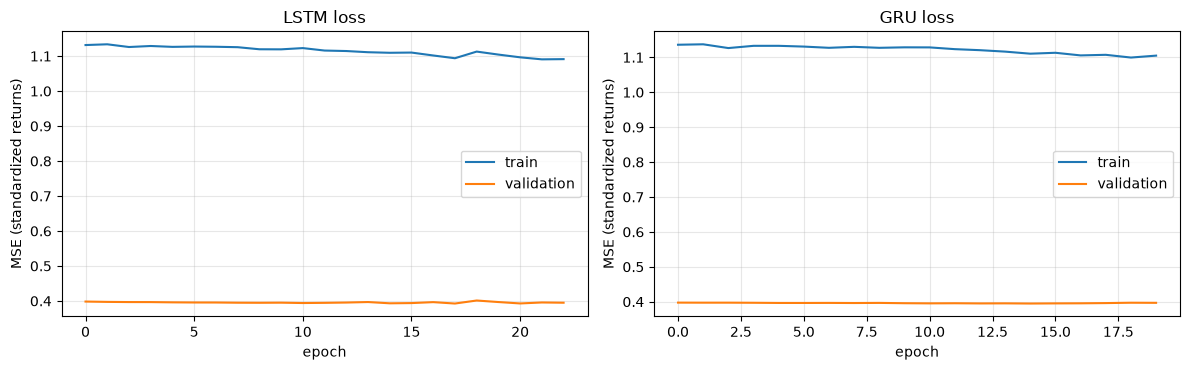

In [15]:
# WHY: train the final LSTM and GRU with the selected hyperparameters; show train/validation loss curves.
X_tr, y_tr = make_windows(z[:split_idx], best_w)
nn_models, hist = {}, {}
for kind in ("LSTM", "GRU"):
    t0 = time.perf_counter()
    m = build(kind, best_w, best_u, best_d)
    hist[kind] = fit(m, X_tr, y_tr)
    cost[kind] += time.perf_counter() - t0
    nn_models[kind] = m

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a_, kind in zip(ax, ("LSTM", "GRU")):
    a_.plot(hist[kind].history["loss"], label="train"); a_.plot(hist[kind].history["val_loss"], label="validation")
    a_.set_title(f"{kind} loss"); a_.set_xlabel("epoch"); a_.set_ylabel("MSE (standardized returns)"); a_.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "06_loss_curves.png", dpi=120); plt.show()

In [16]:
# WHY: walk-forward validation (expanding train window, next block as test) tests how stable the networks are over time.
# Metric: RMSE of the next-day RETURN forecast vs the naive forecast (return = 0). Ratio < 1 means better than naive.
L = int(0.05 * n)
EPOCHS_WF = 3 if QUICK else 25
wf_rows = []
for frac in (0.60, 0.70, 0.80, 0.90):
    cut = int(n * frac)
    mu_c, sd_c = r_all[:cut].mean(), r_all[:cut].std()
    zc = (r_all - mu_c) / sd_c
    Xc, yc = make_windows(zc[:cut], best_w)
    Xt, _ = make_windows(zc[cut - best_w: cut + L], best_w)
    actual = r_all[cut: cut + L]
    rmse_naive = np.sqrt(np.mean(actual ** 2))
    for kind in ("LSTM", "GRU"):
        m = build(kind, best_w, best_u, best_d); fit(m, Xc, yc, epochs=EPOCHS_WF)
        pred = m.predict(Xt, verbose=0)[:, 0] * sd_c + mu_c
        rmse = np.sqrt(np.mean((actual - pred) ** 2))
        wf_rows.append({"Model": kind, "Train up to": f"{int(frac*100)}% ({df.index[cut-1].date()})", "RMSE model": round(rmse, 5),
                        "RMSE naive": round(rmse_naive, 5), "Ratio model/naive": round(rmse / rmse_naive, 3)})
wf_df = pd.DataFrame(wf_rows)
display(wf_df)
for kind in ("LSTM", "GRU"):
    r_ = wf_df[wf_df.Model == kind]["Ratio model/naive"]
    print(f"{kind}: ratio to naive over folds = {r_.mean():.3f} +/- {r_.std():.3f} (min {r_.min():.3f}, max {r_.max():.3f}); "
          f"beats naive in {(r_ < 1).sum()}/{len(r_)} folds.")

,Model,Train up to,RMSE model,RMSE naive,Ratio model/naive
0,LSTM,60% (2023-08-30),0.02868,0.02893,0.992
1,GRU,60% (2023-08-30),0.02870,0.02893,0.992
2,LSTM,70% (2024-06-10),0.03335,0.03322,1.004
3,GRU,70% (2024-06-10),0.03332,0.03322,1.003
4,LSTM,80% (2025-03-24),0.02215,0.02233,0.992
5,GRU,80% (2025-03-24),0.02214,0.02233,0.992
6,LSTM,90% (2025-12-31),0.03130,0.03167,0.988
7,GRU,90% (2025-12-31),0.03135,0.03167,0.990


LSTM: ratio to naive over folds = 0.994 +/- 0.007 (min 0.988, max 1.004); beats naive in 3/4 folds.
GRU: ratio to naive over folds = 0.994 +/- 0.006 (min 0.990, max 1.003); beats naive in 3/4 folds.


**Reading of the walk-forward results:** the ratio to the naive forecast is the honest measure. Ratios close to 1 (or above 1) in several folds mean the network brings no reliable gain over "tomorrow's return = 0". A large spread of the ratio between folds shows **instability**: the result depends on which period is predicted and on the random initialization, so a single good test score would not be trustworthy. This matches the idea that daily returns are almost unpredictable.

**Result on this run:** the ratio to the naive forecast is between 0.988 and 1.004 for both networks in all four folds (mean 0.994, standard deviation 0.006-0.007). So the folds are stable, not erratic, but the networks are only about 0.6 % better than 'return = 0' on average, which is practically the naive forecast. The networks learned almost no predictable signal; their validation MSE is also only about 1.6 % below the zero forecast (grid table above).

### 4.3 Extension: dynamic correlation between gold and Bitcoin
A single correlation hides regime changes. The 60-day rolling correlation of returns shows when the two assets moved together. (Prophet, the additional model, is evaluated in section 5 together with the others.)

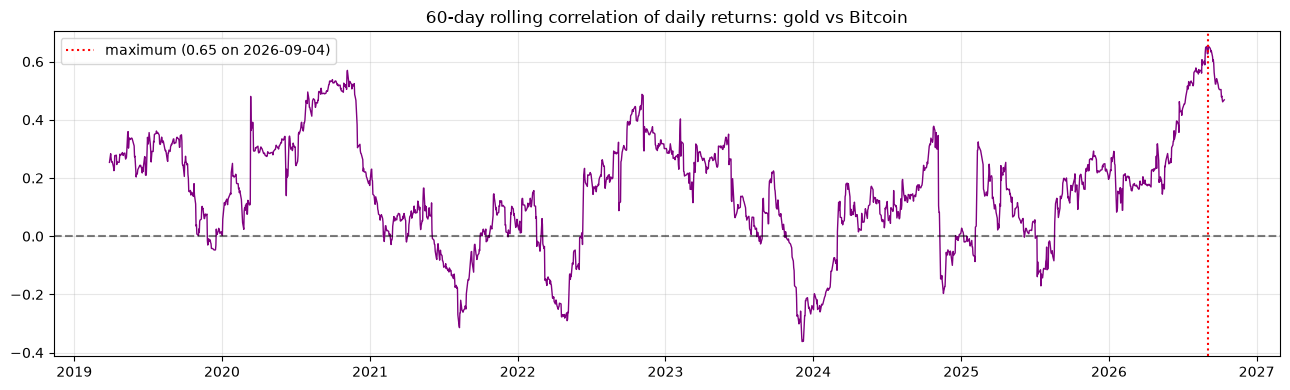

Full-sample correlation: 0.154 | rolling maximum: 0.65 on 2026-09-04 | maximum within March 2020: 0.48 | share of days with negative rolling correlation: 19%
Limit: BTC Monday returns cover Friday-Monday (3 days) because weekends were removed to match gold's calendar.


In [17]:
# WHY: rolling correlation shows regime-dependent co-movement; the peak value and date are COMPUTED, not typed.
roll_corr = df["gold_return"].rolling(60).corr(df["btc_return"]).dropna()
peak_date, peak_val = roll_corr.idxmax(), roll_corr.max()
mar20 = roll_corr.loc["2020-03"].max() if len(roll_corr.loc["2020-03"]) else float("nan")

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(roll_corr.index, roll_corr, color="purple", lw=1)
ax.axhline(0, color="black", ls="--", alpha=0.5)
ax.axvline(peak_date, color="red", ls=":", label=f"maximum ({peak_val:.2f} on {peak_date.date()})")
ax.set_title("60-day rolling correlation of daily returns: gold vs Bitcoin"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "07_rolling_corr.png", dpi=120); plt.show()
print(f"Full-sample correlation: {df['gold_return'].corr(df['btc_return']):.3f} | "
      f"rolling maximum: {peak_val:.2f} on {peak_date.date()} | maximum within March 2020: {mar20:.2f} | "
      f"share of days with negative rolling correlation: {(roll_corr < 0).mean():.0%}")
print("Limit: BTC Monday returns cover Friday-Monday (3 days) because weekends were removed to match gold's calendar.")

**Reading of the rolling correlation:** the maximum of the 60-day rolling correlation is **0.65 on 2026-09-04**, not during the March 2020 crash, where the maximum is only **0.48**. (An earlier version of the project said the +0.65 peak was in March 2020; that was wrong.) The full-sample correlation is low (0.154) and the rolling correlation is negative on 19 % of days, so the link between gold and Bitcoin is weak and unstable, consistent with the absence of Granger causality and cointegration.

## 5. Forecasting and evaluation (h = 1, 5, 10)

**One common protocol for every model (this fixes the unfair comparison of the first version):**
- *Rolling origin.* For each day $t$ of the test period (the origin), every model uses only data up to $t$ and forecasts the log price at $t+1,\dots,t+10$. The real value of day $t$ is then revealed and the origin moves one day forward. All models are scored on the **same origins and the same targets**.
- Models: **Naive** (tomorrow = today, the benchmark), **ARIMA** (orders fixed, parameters updated with each new observation), **VAR** (on returns, cumulated into a log-price forecast, coefficients fixed), **LSTM**, **GRU** (trained once on the training set), **Prophet** (additional model, refitted every 5 days for speed). Gold: Naive, ARIMA, VAR.
- Metrics on the **log price**: MSE, RMSE, MAE. **MAPE is computed on USD prices** (after `exp`), because MAPE on log prices is artificially tiny and MAPE on returns is meaningless (returns are close to 0).
- **GARCH** forecasts volatility, not the price, so it is evaluated on its own target (squared returns) in the same table.
- Significance: **Diebold-Mariano** test on the same horizon, with Newey-West variance (needed for h > 1, where forecast errors overlap) and the Harvey-Leybourne-Newbold small-sample correction.

In [18]:
# WHY: build the common rolling-origin forecasts of the log price for every model, at horizons 1..10.
H = 10
Y = {"Bitcoin": df["btc_logprice"].values, "Gold": df["gold_logprice"].values}
origins = np.arange(split_idx - 1, n - H)           # information up to day t -> forecast t+1..t+10 (all inside the test period)
no = len(origins)
F, CI = {}, {}                                       # F[(model, asset)] -> array (no, H) of log-price forecasts
print(f"{no} forecast origins, each with horizons 1..{H}.")

# --- Naive benchmark: tomorrow = today
for a in Y:
    F[("Naive", a)] = np.repeat(Y[a][origins][:, None], H, axis=1)

# --- ARIMA: same orders, real value added each day with m.update (parameters re-estimated, orders kept)
t0 = time.perf_counter()
for a in Y:
    m = copy.deepcopy(arima_models[a])
    fc, ci = np.zeros((no, H)), np.zeros((no, H, 2))
    for k, t in enumerate(origins):
        fc[k], ci[k] = m.predict(n_periods=H, return_conf_int=True, alpha=0.05)
        m.update(Y[a][t + 1:t + 2])
    F[("ARIMA", a)], CI[("ARIMA", a)] = fc, ci
cost["ARIMA"] += time.perf_counter() - t0

# --- VAR on returns: forecast the next 10 returns, then cumulate them onto the last known log price
R = df[["gold_return", "btc_return"]].values
kk = var_model.k_ar
fr = np.array([var_model.forecast(R[t - kk + 1:t + 1], steps=H) for t in origins])     # (no, H, 2)
for a, j in (("Gold", 0), ("Bitcoin", 1)):
    F[("VAR", a)] = Y[a][origins][:, None] + np.cumsum(fr[:, :, j], axis=1)

# --- LSTM / GRU: recursive multi-step forecast of standardized returns, cumulated onto the last log price
for kind in ("LSTM", "GRU"):
    t0 = time.perf_counter()
    W = np.stack([z[t - best_w + 1:t + 1] for t in origins])[:, :, None]
    preds = []
    for _ in range(H):
        p = nn_models[kind].predict(W, verbose=0)[:, 0]
        preds.append(p)
        W = np.concatenate([W[:, 1:, :], p[:, None, None]], axis=1)
    r_hat = np.stack(preds, axis=1) * sd + mu
    F[(kind, "Bitcoin")] = Y["Bitcoin"][origins][:, None] + np.cumsum(r_hat, axis=1)
    cost[kind] += time.perf_counter() - t0

187 forecast origins, each with horizons 1..10.


In [19]:
# WHY: Prophet (additional model). A full refit at every origin is slow, so it is refitted every REFIT days; the forecast for a later origin
# uses the latest fit made BEFORE that origin (no future information is used).
from prophet import Prophet
for _n in ("cmdstanpy", "prophet"):                 # hide Prophet fitting logs
    _lg = logging.getLogger(_n); _lg.handlers = []; _lg.propagate = False; _lg.disabled = True

REFIT = 10 if QUICK else 5
F_prophet = np.zeros((no, H))
t0 = time.perf_counter()
for k0 in range(0, no, REFIT):
    s_ = origins[k0]
    last = min(s_ + H + REFIT - 1, n - 1)
    mp = Prophet(daily_seasonality=False, weekly_seasonality=False, yearly_seasonality=True, changepoint_prior_scale=0.05)
    mp.fit(pd.DataFrame({"ds": df.index[:s_ + 1], "y": Y["Bitcoin"][:s_ + 1]}))
    yhat = mp.predict(pd.DataFrame({"ds": df.index[s_ + 1:last + 1]}))["yhat"].values   # yhat[j] targets day s_+1+j
    for k in range(k0, min(k0 + REFIT, no)):
        off = origins[k] - s_
        F_prophet[k] = yhat[off:off + H]
F[("Prophet", "Bitcoin")] = F_prophet
cost["Prophet"] += time.perf_counter() - t0
print("Prophet done.")

Prophet done.


In [20]:
# WHY: one summary table with all models. MAPE is on USD prices only. GARCH is added on its own target (squared returns, 1-step variance).
def metrics(actual_log, pred_log):
    e = actual_log - pred_log
    mape = 100 * np.mean(np.abs(np.exp(actual_log) - np.exp(pred_log)) / np.exp(actual_log))
    return {"MSE": np.mean(e ** 2), "RMSE": np.sqrt(np.mean(e ** 2)), "MAE": np.mean(np.abs(e)), "MAPE (USD, %)": mape}

E = {}                                              # forecast errors, kept for the Diebold-Mariano test
rows = []
for (model, a), fc in F.items():
    for h in (1, 5, 10):
        actual = Y[a][origins + h]
        E[(model, a, h)] = actual - fc[:, h - 1]
        rows.append({"Asset": a, "Model": model, "Target": "log price", "h": h, **metrics(actual, fc[:, h - 1])})
summary = pd.DataFrame(rows)
naive_rmse = summary[summary.Model == "Naive"].set_index(["Asset", "h"])["RMSE"]
summary["RMSE / naive"] = [r.RMSE / naive_rmse[(r.Asset, r.h)] for r in summary.itertuples()]

# GARCH: conditional variance forecast one day ahead (parameters fixed from the training fit, filtered over the test period),
# compared with the squared return, against a constant-variance benchmark (training variance). Units: (%)^2.
g_rows = []
for col, a in [("gold_return", "Gold"), ("btc_return", "Bitcoin")]:
    res, dist = garch_best[a]
    fixed = arch_model(df[col] * 100, mean="Constant", vol="GARCH", p=1, q=1, dist=dist).fix(res.params)
    s2 = (fixed.conditional_volatility ** 2).iloc[split_idx:].values
    r2 = (df[col].iloc[split_idx:].values * 100) ** 2
    const = np.full_like(r2, (train[col] * 100).var())
    for model, fcv in (("GARCH(1,1)", s2), ("Constant variance", const)):
        e = r2 - fcv
        g_rows.append({"Asset": a, "Model": model, "Target": "squared return (%^2)", "h": 1, "MSE": np.mean(e ** 2),
                       "RMSE": np.sqrt(np.mean(e ** 2)), "MAE": np.mean(np.abs(e)), "MAPE (USD, %)": np.nan, "RMSE / naive": np.nan})
summary_all = pd.concat([summary, pd.DataFrame(g_rows)], ignore_index=True)
summary_all.to_csv(DATA_DIR / "forecast_summary.csv", index=False)
pd.options.display.float_format = "{:.5g}".format
display(summary_all)

print("\nRMSE / naive (log price): below 1 = better than 'tomorrow = today'")
display(summary[summary.Model != "Naive"].pivot_table(index=["Asset", "Model"], columns="h", values="RMSE / naive").round(3))

,Asset,Model,Target,h,MSE,RMSE,MAE,"MAPE (USD, %)",RMSE / naive
0,Bitcoin,Naive,log price,1,0.00082175,0.028666,0.019814,1.9825,1
1,Bitcoin,Naive,log price,5,0.0044599,0.066783,0.048073,4.8458,1
2,Bitcoin,Naive,log price,10,0.0097481,0.098732,0.071419,7.2895,1
3,Gold,Naive,log price,1,0.00038902,0.019724,0.014512,1.4549,1
4,Gold,Naive,log price,5,0.0017376,0.041685,0.032278,3.2405,1
5,Gold,Naive,log price,10,0.0029445,0.054263,0.042271,4.2444,1
6,Bitcoin,ARIMA,log price,1,0.00083836,0.028954,0.020078,2.0125,1.0101
7,Bitcoin,ARIMA,log price,5,0.0045983,0.067811,0.048718,4.95,1.0154
8,Bitcoin,ARIMA,log price,10,0.010262,0.1013,0.073154,7.5825,1.026
9,Gold,ARIMA,log price,1,0.00038987,0.019745,0.014485,1.4532,1.0011



RMSE / naive (log price): below 1 = better than 'tomorrow = today'


h                  1     5     10
Asset   Model                    
Bitcoin ARIMA    1.01 1.015 1.026
        GRU      0.99 1.003 1.006
        LSTM    0.986 1.025 1.032
        Prophet 10.04 4.693 3.425
        VAR     1.005 1.014 1.026
Gold    ARIMA   1.001 1.007 1.018
        VAR     1.001 1.006 1.017

In [21]:
# WHY: Diebold-Mariano test on the SAME horizon, with Newey-West variance (Bartlett weights, h-1 lags) and the HLN correction.
from scipy.stats import t as t_dist

def dm_test(e1, e2, h):
    d = e1 ** 2 - e2 ** 2                              # squared-error loss differential; d < 0 means model 1 is better
    T = len(d); dc = d - d.mean()
    var = np.mean(dc * dc)
    for k in range(1, h):
        var += 2 * (1 - k / h) * np.mean(dc[k:] * dc[:-k])
    var /= T
    if var <= 0:
        return np.nan, np.nan
    dm = d.mean() / np.sqrt(var) * np.sqrt((T + 1 - 2 * h + h * (h - 1) / T) / T)
    return dm, 2 * t_dist.sf(abs(dm), df=T - 1)

pairs = [(m, "Naive", a) for a in Y for m in ("ARIMA", "VAR") ] + [(m, "Naive", "Bitcoin") for m in ("LSTM", "GRU", "Prophet")] \
        + [("LSTM", "ARIMA", "Bitcoin"), ("GRU", "ARIMA", "Bitcoin"), ("GRU", "LSTM", "Bitcoin")]
rows = []
for m1, m2, a in pairs:
    for h in (1, 5, 10):
        dm, p = dm_test(E[(m1, a, h)], E[(m2, a, h)], h)
        verdict = "no significant difference" if (np.isnan(p) or p >= 0.05) else (f"{m1} better" if dm < 0 else f"{m2} better")
        rows.append({"Asset": a, "Model 1": m1, "Model 2": m2, "h": h, "DM stat": round(dm, 3), "p-value": round(p, 4), "Verdict (5%)": verdict})
dm_df = pd.DataFrame(rows)
dm_df.to_csv(DATA_DIR / "diebold_mariano.csv", index=False)
display(dm_df)

,Asset,Model 1,Model 2,h,DM stat,p-value,Verdict (5%)
0,Bitcoin,ARIMA,Naive,1,1.128,0.2606,no significant difference
1,Bitcoin,ARIMA,Naive,5,0.883,0.3783,no significant difference
2,Bitcoin,ARIMA,Naive,10,0.765,0.4453,no significant difference
3,Bitcoin,VAR,Naive,1,0.621,0.5352,no significant difference
4,Bitcoin,VAR,Naive,5,0.736,0.4628,no significant difference
5,Bitcoin,VAR,Naive,10,0.691,0.4906,no significant difference
6,Gold,ARIMA,Naive,1,0.426,0.6708,no significant difference
7,Gold,ARIMA,Naive,5,0.646,0.5194,no significant difference
8,Gold,ARIMA,Naive,10,0.753,0.4523,no significant difference
9,Gold,VAR,Naive,1,0.464,0.6432,no significant difference


,Asset,h,mean 95% interval width (log),empirical coverage (target 95%)
0,Bitcoin,1,0.1542,98.4%
1,Bitcoin,5,0.3384,95.7%
2,Bitcoin,10,0.4776,96.3%
3,Gold,1,0.0426,78.6%
4,Gold,5,0.0952,80.2%
5,Gold,10,0.1346,82.4%


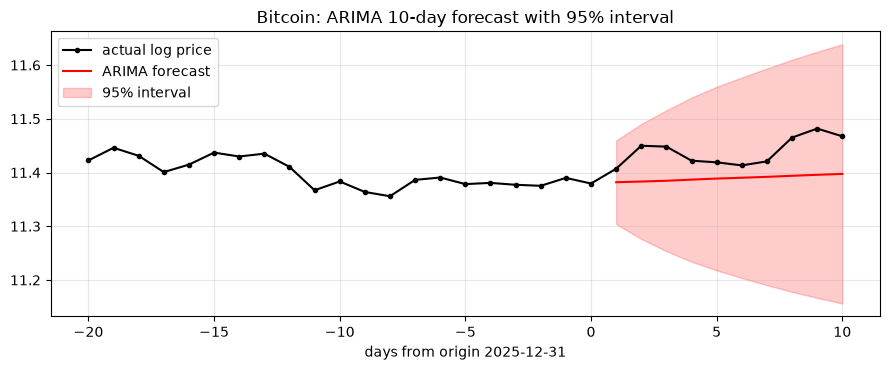

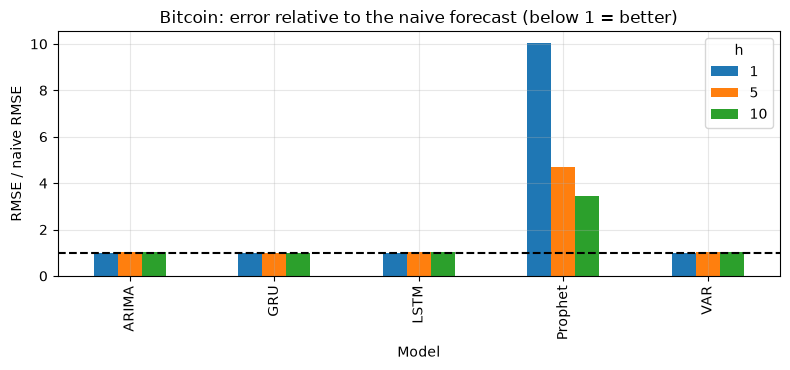

In [22]:
# WHY: prediction intervals. ARIMA gives 95% intervals; I check how often the real value falls inside them (empirical coverage).
rows = []
for a in Y:
    ci = CI[("ARIMA", a)]
    for h in (1, 5, 10):
        actual = Y[a][origins + h]
        inside = (actual >= ci[:, h - 1, 0]) & (actual <= ci[:, h - 1, 1])
        rows.append({"Asset": a, "h": h, "mean 95% interval width (log)": round((ci[:, h - 1, 1] - ci[:, h - 1, 0]).mean(), 4),
                     "empirical coverage (target 95%)": f"{inside.mean():.1%}"})
display(pd.DataFrame(rows))

# example: one 10-day forecast fan from the first test origin (Bitcoin)
k = 0; t = origins[k]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(range(-20, H + 1), Y["Bitcoin"][t - 20:t + H + 1], "k-o", ms=3, label="actual log price")
ax.plot(range(1, H + 1), F[("ARIMA", "Bitcoin")][k], "r-", label="ARIMA forecast")
ax.fill_between(range(1, H + 1), CI[("ARIMA", "Bitcoin")][k, :, 0], CI[("ARIMA", "Bitcoin")][k, :, 1], color="r", alpha=0.2, label="95% interval")
ax.set_xlabel(f"days from origin {df.index[t].date()}"); ax.set_title("Bitcoin: ARIMA 10-day forecast with 95% interval"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "08_arima_fan.png", dpi=120); plt.show()

# RMSE / naive per horizon (Bitcoin)
piv = summary[(summary.Asset == "Bitcoin") & (summary.Model != "Naive")].pivot_table(index="Model", columns="h", values="RMSE / naive")
piv.plot(kind="bar", figsize=(8, 3.8)); plt.axhline(1, color="k", ls="--"); plt.ylabel("RMSE / naive RMSE")
plt.title("Bitcoin: error relative to the naive forecast (below 1 = better)"); plt.tight_layout()
plt.savefig(FIG_DIR / "09_rmse_ratio.png", dpi=120); plt.show()

In [23]:
# WHY: comparison table asked by the cahier: performance, complexity, interpretability and cost (Bitcoin).
b = summary[summary.Asset == "Bitcoin"].pivot_table(index="Model", columns="h", values="RMSE")
comp = pd.DataFrame({
    "RMSE h=1": b[1], "RMSE h=5": b[5], "RMSE h=10": b[10],
    "Complexity": {"Naive": "0 parameters", "ARIMA": f"ARIMA{arima_models['Bitcoin'].order}", "VAR": f"VAR({var_lag}) on 2 series",
                   "LSTM": f"{nn_models['LSTM'].count_params()} parameters", "GRU": f"{nn_models['GRU'].count_params()} parameters",
                   "Prophet": "trend + yearly seasonality"},
    "Interpretability": {"Naive": "very high", "ARIMA": "high", "VAR": "high", "LSTM": "low (black box)", "GRU": "low (black box)", "Prophet": "medium (components)"},
    "Compute time (s)": {k: round(cost.get(k, 0.0), 1) for k in b.index},
}).round(4)
display(comp)
comp.to_csv(DATA_DIR / "model_comparison_bitcoin.csv")

,RMSE h=1,RMSE h=5,RMSE h=10,Complexity,Interpretability,Compute time (s)
ARIMA,0.029,0.0678,0.1013,"ARIMA(2, 1, 2)",high,124.3
GRU,0.0284,0.067,0.0994,8001 parameters,low (black box),26.9
LSTM,0.0283,0.0685,0.1019,10451 parameters,low (black box),24.2
Naive,0.0287,0.0668,0.0987,0 parameters,very high,0
Prophet,0.2878,0.3134,0.3382,trend + yearly seasonality,medium (components),54
VAR,0.0288,0.0677,0.1013,VAR(1) on 2 series,high,0


In [24]:
# WHY: the conclusion is GENERATED from the metrics and the DM tests, so it cannot contradict the tables.
print("BEST MODEL PER ASSET AND HORIZON (lowest RMSE on log price), and is it significantly better than naive (DM, 5%)?\n")
for a in ("Bitcoin", "Gold"):
    for h in (1, 5, 10):
        sub = summary[(summary.Asset == a) & (summary.h == h)].sort_values("RMSE")
        best = sub.iloc[0]
        if best.Model == "Naive":
            line = "the naive forecast is the best: no model beats 'tomorrow = today'."
        else:
            r = dm_df[(dm_df.Asset == a) & (dm_df["Model 1"] == best.Model) & (dm_df["Model 2"] == "Naive") & (dm_df.h == h)].iloc[0]
            line = (f"{best.Model} (RMSE {best.RMSE:.4f} vs naive {sub[sub.Model=='Naive'].RMSE.iloc[0]:.4f}); "
                    f"vs naive: DM p = {r['p-value']:.3f} -> {'significantly better' if (r['p-value'] < 0.05 and r['DM stat'] < 0) else 'NOT significantly better'}.")
        print(f"{a}, h={h}: {line}")

print("\nVOLATILITY (squared-return forecast, 1 day ahead):")
garch_wins = []
for a in ("Gold", "Bitcoin"):
    g = summary_all[(summary_all.Asset == a) & (summary_all.Target.str.startswith("squared"))].set_index("Model")["RMSE"]
    garch_wins.append(g["GARCH(1,1)"] < g["Constant variance"])
    print(f"  {a}: GARCH RMSE {g['GARCH(1,1)']:.4g} vs constant variance {g['Constant variance']:.4g} "
          f"-> {'GARCH better' if garch_wins[-1] else 'constant variance better'}.")

sig = dm_df[(dm_df["Model 2"] == "Naive") & (dm_df["p-value"] < 0.05) & (dm_df["DM stat"] < 0)]
tot = dm_df[dm_df["Model 2"] == "Naive"]
print(f"\nPRICE FORECASTS: a model is significantly better than naive in {len(sig)} of {len(tot)} (model, asset, horizon) comparisons"
      + (": " + "; ".join(f"{r['Model 1']} on {r['Asset']} (h={r['h']})" for _, r in sig.iterrows()) if len(sig) else "."))
print("CHOICE: prefer the simplest model that is not significantly worse than the best one (naive / ARIMA / VAR: interpretable, almost free to compute) "
      "over LSTM, GRU or Prophet unless the table above shows a significant gain. "
      + ("GARCH improves the variance forecast for both assets, so it is kept for risk measurement." if all(garch_wins)
         else "GARCH did not beat constant variance for every asset: check the volatility lines above before using it."))

BEST MODEL PER ASSET AND HORIZON (lowest RMSE on log price), and is it significantly better than naive (DM, 5%)?

Bitcoin, h=1: LSTM (RMSE 0.0283 vs naive 0.0287); vs naive: DM p = 0.642 -> NOT significantly better.
Bitcoin, h=5: the naive forecast is the best: no model beats 'tomorrow = today'.
Bitcoin, h=10: the naive forecast is the best: no model beats 'tomorrow = today'.
Gold, h=1: the naive forecast is the best: no model beats 'tomorrow = today'.
Gold, h=5: the naive forecast is the best: no model beats 'tomorrow = today'.
Gold, h=10: the naive forecast is the best: no model beats 'tomorrow = today'.

VOLATILITY (squared-return forecast, 1 day ahead):
  Gold: GARCH RMSE 9.455 vs constant variance 9.919 -> GARCH better.
  Bitcoin: GARCH RMSE 21.68 vs constant variance 22.79 -> GARCH better.

PRICE FORECASTS: a model is significantly better than naive in 0 of 21 (model, asset, horizon) comparisons.
CHOICE: prefer the simplest model that is not significantly worse than the best one 

**Reading of the results (this run, see the tables above):**
- **No model beats the naive forecast.** 0 of 21 Diebold-Mariano comparisons against "tomorrow = today" are significant in favour of a model. The best RMSE/naive ratios are 0.986 (LSTM, Bitcoin, h=1) and 0.990 (GRU, h=1), differences far from significant (p = 0.64 and 0.37). For h = 5 and 10 and for gold, naive has the lowest RMSE. This is the expected result for liquid assets (weak-form efficiency), and it is a valid scientific conclusion.
- **Prophet is much worse** (RMSE/naive about 10 at h=1, 3.4 at h=10). Most likely cause: Prophet fits a smooth trend + yearly curve and does not anchor on the last observed price, so its level error stays large. It is useful for decomposition, not for short-horizon price forecasts.
- **ARIMA(2,1,2) for Bitcoin was chosen by AIC** (-6345.3 vs -6341.9 for the manual (0,1,0)), but BIC clearly prefers (0,1,0) (-6330.9 vs -6312.5), and in forecasting ARIMA(2,1,2) is slightly worse than naive. The extra terms bring no real gain: parsimony (BIC, naive) wins.
- **Volatility is the predictable part, but modestly:** GARCH beats constant variance by about 5 % in RMSE on squared returns (gold 9.46 vs 9.92; Bitcoin 21.7 vs 22.8). Bitcoin persistence is 0.996, close to an integrated process, and the ARCH-LM p-value of its standardized residuals (0.074) is above 0.05 but borderline, so the fit is acceptable, not perfect.
- **Naive h=1 error is about twice as large for gold in the test period** as the training residual std, hence the poor interval coverage for gold (section 7).

## 6. Generative AI / LLM (cahier section 5, 4 points)

Order of work: (1) statistics (6.1); (2) my own interpretation (6.2); (3) prompts built from the real results and saved in `llm/` (6.3); (4) full prompts and answers (6.4); (5) comparison and error audit (6.5); (6) vulgarized annex (6.6).

**LLM used:** Claude Sonnet 5.5 (claude.ai), one conversation, the three prompts sent in order.

In [25]:
# 6.1 WHY: the descriptive statistics and test results that will be given to the LLM (and used later to check its claims).
moments_df = pd.DataFrame([{"Asset": a, "mean": train[c].mean(), "variance": train[c].var(), "std": train[c].std(),
                            "skewness": stats.skew(train[c]), "excess kurtosis": stats.kurtosis(train[c])}
                           for a, c in [("Gold", "gold_return"), ("Bitcoin", "btc_return")]])
display(moments_df.round(6)); display(stat_df); display(arima_diag[["Asset", "Final order", "Test", "p-value", "Reading"]])
display(granger_df); display(coint_df); display(garch_df)

,Asset,mean,variance,std,skewness,excess kurtosis
0,Gold,0.000673,9.9e-05,0.009938,-0.41563,3.2983
1,Bitcoin,0.001762,0.001585,0.03981,-0.92519,14.051


,Series,ADF p-value,KPSS p-value,Conclusion
0,Gold price,1,0.0001,Non-stationary
1,Gold log price,0.9944,0.0001,Non-stationary
2,Gold return,0,0.0935,Stationary
3,Bitcoin price,0.633,0.0001,Non-stationary
4,Bitcoin log price,0.3283,0.0001,Non-stationary
5,Bitcoin return,0,0.3843,Stationary


,Asset,Final order,Test,p-value,Reading
0,Gold,"(0, 1, 0)",Ljung-Box (10),0.743,no remaining autocorrelation
1,Gold,"(0, 1, 0)",Jarque-Bera,9.61e-185,normality rejected (fat tails)
2,Gold,"(0, 1, 0)",ARCH-LM (10),5.27e-19,ARCH effect present
3,Bitcoin,"(2, 1, 2)",Ljung-Box (10),0.441,no remaining autocorrelation
4,Bitcoin,"(2, 1, 2)",Jarque-Bera,0,normality rejected (fat tails)
5,Bitcoin,"(2, 1, 2)",ARCH-LM (10),0.000223,ARCH effect present


,Direction,F-stat,p-value,Conclusion
0,Gold -> Bitcoin,0.119,0.7298,No Granger causality (p >= 0.05)
1,Bitcoin -> Gold,0.006,0.9365,No Granger causality (p >= 0.05)


,Test,Statistic,p-value,Conclusion
0,Engle-Granger (log prices),-0.266,0.9774,Not cointegrated (p = 0.9774 >= 0.05)


,Asset,Distribution,alpha,beta,Persistence,AIC,ARCH-LM p (std. resid),Std. residuals
0,Gold,normal,0.105,0.835,0.94,4792,0.7986,no ARCH left
1,Gold,t,0.072,0.891,0.963,4715.8,0.7495,no ARCH left
2,Bitcoin,normal,0.136,0.782,0.918,9681,0.1369,no ARCH left
3,Bitcoin,t,0.067,0.929,0.996,9274.3,0.0744,no ARCH left



### 6.2 My own expert interpretation (written before using the LLM)
> **DRAFT: before you submit, rewrite this in your own words and make sure it was written before you read the LLM answers (the cahier checks this).**

*Distributions.* Gold returns have a daily standard deviation of about 1 % and moderate fat tails (excess kurtosis 3.3). Bitcoin's is about 4 % with very heavy tails (excess kurtosis 14.1) and negative skewness (-0.93), so a normal distribution is not acceptable, especially for Bitcoin; extreme losses such as March 2020 weigh heavily.

*Stationarity.* ADF and KPSS agree: prices and log prices are non-stationary, returns are stationary, so d = 1 and I model log prices with one difference (equivalently, returns). Gold's return KPSS p-value (0.094) is close to 0.05, so that conclusion is a bit less firm.

*Residuals.* The ARIMA residuals have no remaining autocorrelation (Ljung-Box p = 0.74 and 0.44), so the mean model is adequate, but normality is strongly rejected and ARCH effects are present. This motivates GARCH with a Student-t distribution, which leaves no ARCH in the standardized residuals. Bitcoin volatility is almost integrated (persistence 0.996).

*Interactions.* No Granger causality (p = 0.73 and 0.94) and no cointegration (p = 0.98), so no VECM; the rolling correlation is unstable (maximum 0.65 on 2026-09-04, negative on 19 % of days).

*Expectation.* Because returns are almost unpredictable, I expect the naive forecast to be very hard to beat, and the neural networks to add little. What I can model is the volatility (risk), not the direction. I do not trust any gain below a few percent without a significance test.


In [26]:
# 6.3 WHY: build the three prompts from the REAL results and save them. Paste each one into the LLM (same conversation, in this order).
def tbl(d): return d.to_string(index=False)

p1 = f"""You are an expert in time-series econometrics. Here are the descriptive statistics of daily log returns (train sample 2019-2026, business days)
and the stationarity tests (ADF H0 = unit root; KPSS H0 = stationary).

DESCRIPTIVE STATISTICS
{tbl(moments_df.round(6))}

STATIONARITY TESTS
{tbl(stat_df)}

TASK: (1) Propose 4 to 6 candidate model families to test for each asset and justify each from the numbers above.
(2) For each candidate, say which diagnostic test would validate or reject it. (3) Do NOT invent any numerical result: if you need a number I did not give, say so."""

p2 = f"""Here are the results of my models on gold (GLD) and Bitcoin.

ARIMA RESIDUAL TESTS
{tbl(arima_diag[['Asset','Final order','Test','Statistic','p-value','Reading']])}

GRANGER CAUSALITY (VAR on returns)
{tbl(granger_df)}

COINTEGRATION
{tbl(coint_df)}

GARCH(1,1)
{tbl(garch_df)}

FORECAST COMPARISON, RMSE / naive RMSE (log price, below 1 = better than 'tomorrow = today')
{tbl(summary[summary.Model != 'Naive'].pivot_table(index=['Asset','Model'], columns='h', values='RMSE / naive').round(3).reset_index())}

TASK: explain these results to a non-statistician decision maker (a company treasurer), in about 300 words, with simple images or analogies
and no unexplained jargon. State clearly what the results do NOT show."""

p3 = f"""Using ONLY the results below, write simulated investment recommendations for a portfolio holding gold and Bitcoin.

{tbl(summary[summary.Model != 'Naive'].pivot_table(index=['Asset','Model'], columns='h', values='RMSE / naive').round(3).reset_index())}

Volatility model: GARCH(1,1) persistence: {tbl(garch_df[['Asset','Distribution','Persistence']])}
Cointegration: {coint_df['Conclusion'].iloc[0]}. Granger: {', '.join(granger_df['Direction'] + ': ' + granger_df['Conclusion'])}.

TASK: give 3 recommendations, and for each one list YOURSELF its limits and risks."""

for name, text in (("prompt_1_hypotheses", p1), ("prompt_2_vulgarization", p2), ("prompt_3_recommendations", p3)):
    (LLM_DIR / f"{name}.txt").write_text(text, encoding="utf-8")
    print("=" * 30, name, "=" * 30); print(text, "\n")
print("Prompts saved in", LLM_DIR.resolve())

============================== prompt_1_hypotheses ==============================
You are an expert in time-series econometrics. Here are the descriptive statistics of daily log returns (train sample 2019-2026, business days)
and the stationarity tests (ADF H0 = unit root; KPSS H0 = stationary).

DESCRIPTIVE STATISTICS
  Asset     mean  variance      std  skewness  excess kurtosis
   Gold 0.000673   9.9e-05 0.009938  -0.41563           3.2983
Bitcoin 0.001762  0.001585  0.03981  -0.92519           14.051

STATIONARITY TESTS
           Series  ADF p-value  KPSS p-value     Conclusion
       Gold price            1        0.0001 Non-stationary
   Gold log price       0.9944        0.0001 Non-stationary
      Gold return            0        0.0935     Stationary
    Bitcoin price        0.633        0.0001 Non-stationary
Bitcoin log price       0.3283        0.0001 Non-stationary
   Bitcoin return            0        0.3843     Stationary

TASK: (1) Propose 4 to 6 candidate model families

In [27]:
# 6.3b WHY: a 'ground truth' table with the real values, to check every number or claim in the LLM answers.
truth = pd.DataFrame([
    ("ADF p-value, Bitcoin log price", stat_df.set_index("Series").loc["Bitcoin log price", "ADF p-value"]),
    ("KPSS p-value, Bitcoin log price", stat_df.set_index("Series").loc["Bitcoin log price", "KPSS p-value"]),
    ("Granger Gold -> Bitcoin, p", granger_df.iloc[0]["p-value"]), ("Granger Bitcoin -> Gold, p", granger_df.iloc[1]["p-value"]),
    ("Engle-Granger p", coint_df.iloc[0]["p-value"]),
    ("Max rolling correlation", round(peak_val, 3)), ("Bitcoin excess kurtosis", round(moments_df.iloc[1]["excess kurtosis"], 2)),
    ("Bitcoin GARCH persistence", garch_df[(garch_df.Asset == "Bitcoin") & (garch_df.Distribution == garch_best["Bitcoin"][1])]["Persistence"].iloc[0]),
], columns=["Fact", "Real value"])
truth.to_csv(LLM_DIR / "ground_truth.csv", index=False)
display(truth)

,Fact,Real value
0,"ADF p-value, Bitcoin log price",0.3283
1,"KPSS p-value, Bitcoin log price",0.0001
2,"Granger Gold -> Bitcoin, p",0.7298
3,"Granger Bitcoin -> Gold, p",0.9365
4,Engle-Granger p,0.9774
5,Max rolling correlation,0.653
6,Bitcoin excess kurtosis,14.05
7,Bitcoin GARCH persistence,0.996



### 6.4 Prompts and full LLM answers
**LLM used:** Claude Sonnet 5.5 (claude.ai). The exact prompts are also saved in `llm/prompt_1_hypotheses.txt`, `prompt_2_vulgarization.txt`, `prompt_3_recommendations.txt`.

#### Prompt 1: hypotheses
```
You are an expert in time-series econometrics. Here are the descriptive statistics of daily log returns (train sample 2019-2026, business days)
and the stationarity tests (ADF H0 = unit root; KPSS H0 = stationary).

DESCRIPTIVE STATISTICS
  Asset     mean  variance      std  skewness  excess kurtosis
   Gold 0.000673   9.9e-05 0.009938  -0.41563           3.2983
Bitcoin 0.001762  0.001585  0.03981  -0.92519           14.051

STATIONARITY TESTS
           Series  ADF p-value  KPSS p-value     Conclusion
       Gold price            1        0.0001 Non-stationary
   Gold log price       0.9944        0.0001 Non-stationary
      Gold return            0        0.0935     Stationary
    Bitcoin price        0.633        0.0001 Non-stationary
Bitcoin log price       0.3283        0.0001 Non-stationary
   Bitcoin return            0        0.3843     Stationary

TASK: (1) Propose 4 to 6 candidate model families to test for each asset and justify each from the numbers above.
(2) For each candidate, say which diagnostic test would validate or reject it. (3) Do NOT invent any numerical result: if you need a number I did not give, say so.
```
**Answer 1 (full):**

**What the numbers say**
- Both log prices are non-stationary: ADF does not reject a unit root (p = 0.99 gold, 0.33 Bitcoin) and KPSS rejects stationarity (p = 0.0001). Both returns are stationary: ADF rejects (p ≈ 0) and KPSS does not reject. Gold's KPSS p-value (0.0935) is only just above 0.05, so the conclusion is borderline at the 10% level. This suggests d = 1 on log prices.
- Bitcoin has much heavier tails and more skew than gold (excess kurtosis 14.05 vs 3.30, skewness -0.93 vs -0.42) and about 4 times the daily standard deviation (0.0398 vs 0.0099). A normal distribution is not credible for either asset, and especially not for Bitcoin.

**Candidate models (for each asset, unless noted)**

| # | Model | Justification from the numbers | Test that validates or rejects it |
|---|---|---|---|
| 1 | Random walk with drift, ARIMA(0,1,0) | d = 1 and returns that are stationary; the natural baseline | Ljung-Box on residuals; compare out-of-sample with the naive forecast (Diebold-Mariano) |
| 2 | ARIMA(p,1,q) | Allows short-term linear dependence; I need the ACF/PACF to choose p and q | Ljung-Box on residuals; AIC/BIC against model 1 |
| 3 | ARMA-GARCH(1,1) with Student-t errors | Excess kurtosis of 3.30 and 14.05 points to fat tails and probably clustered volatility | ARCH-LM on the mean-model residuals (I do not have this number) and on the standardized residuals; alpha + beta < 1; AIC of Student-t vs normal |
| 4 | Asymmetric GARCH (GJR or EGARCH), especially for Bitcoin | Negative skewness (-0.93) suggests bad news may raise volatility more than good news | Significance of the asymmetry parameter; sign-bias test; AIC against model 3 |
| 5 | VAR on the two return series + Granger tests | The two assets may interact | Lag choice by AIC/BIC; Granger F-tests; portmanteau test on VAR residuals |
| 6 | Cointegration (Engle-Granger or Johansen) and VECM, only if cointegrated | Both log prices are I(1), so they could share a long-run relation | Cointegration test; estimate a VECM only if the null of no cointegration is rejected |

A neural network (LSTM or GRU) is a possible seventh candidate for Bitcoin. It is only worth keeping if it beats the naive forecast in walk-forward validation.

**Numbers I did not receive and would need:** the ACF/PACF of the returns, the ARCH-LM result on the mean-model residuals, and any out-of-sample results. I have not guessed these.

#### Prompt 2: explanation for a decision maker
```
Here are the results of my models on gold (GLD) and Bitcoin.

ARIMA RESIDUAL TESTS
  Asset Final order           Test  Statistic   p-value                        Reading
   Gold   (0, 1, 0) Ljung-Box (10)      6.813     0.743   no remaining autocorrelation
   Gold   (0, 1, 0)    Jarque-Bera      847.4 9.61e-185 normality rejected (fat tails)
   Gold   (0, 1, 0)   ARCH-LM (10)     110.03  5.27e-19            ARCH effect present
Bitcoin   (2, 1, 2) Ljung-Box (10)      9.994     0.441   no remaining autocorrelation
Bitcoin   (2, 1, 2)    Jarque-Bera      13697         0 normality rejected (fat tails)
Bitcoin   (2, 1, 2)   ARCH-LM (10)     33.521  0.000223            ARCH effect present

GRANGER CAUSALITY (VAR on returns)
      Direction  F-stat  p-value                       Conclusion
Gold -> Bitcoin   0.119   0.7298 No Granger causality (p >= 0.05)
Bitcoin -> Gold   0.006   0.9365 No Granger causality (p >= 0.05)

COINTEGRATION
                      Test  Statistic  p-value                            Conclusion
Engle-Granger (log prices)     -0.266   0.9774 Not cointegrated (p = 0.9774 >= 0.05)

GARCH(1,1)
  Asset Distribution  alpha  beta  Persistence    AIC  ARCH-LM p (std. resid) Std. residuals
   Gold       normal  0.105 0.835         0.94   4792                  0.7986   no ARCH left
   Gold            t  0.072 0.891        0.963 4715.8                  0.7495   no ARCH left
Bitcoin       normal  0.136 0.782        0.918   9681                  0.1369   no ARCH left
Bitcoin            t  0.067 0.929        0.996 9274.3                  0.0744   no ARCH left

FORECAST COMPARISON, RMSE / naive RMSE (log price, below 1 = better than 'tomorrow = today')
  Asset   Model     1     5    10
Bitcoin   ARIMA  1.01 1.015 1.026
Bitcoin     GRU  0.99 1.003 1.006
Bitcoin    LSTM 0.986 1.025 1.032
Bitcoin Prophet 10.04 4.693 3.425
Bitcoin     VAR 1.005 1.014 1.026
   Gold   ARIMA 1.001 1.007 1.018
   Gold     VAR 1.001 1.006 1.017

TASK: explain these results to a non-statistician decision maker (a company treasurer), in about 300 words, with simple images or analogies
and no unexplained jargon. State clearly what the results do NOT show.
```
**Answer 2:** see the annex, section 6.6.

#### Prompt 3: recommendations (limits written by the LLM itself)
```
Using ONLY the results below, write simulated investment recommendations for a portfolio holding gold and Bitcoin.

  Asset   Model     1     5    10
Bitcoin   ARIMA  1.01 1.015 1.026
Bitcoin     GRU  0.99 1.003 1.006
Bitcoin    LSTM 0.986 1.025 1.032
Bitcoin Prophet 10.04 4.693 3.425
Bitcoin     VAR 1.005 1.014 1.026
   Gold   ARIMA 1.001 1.007 1.018
   Gold     VAR 1.001 1.006 1.017

Volatility model: GARCH(1,1) persistence:   Asset Distribution  Persistence
   Gold       normal  0.94
   Gold            t  0.963
Bitcoin       normal  0.918
Bitcoin            t  0.996
Cointegration: Not cointegrated (p = 0.9774 >= 0.05). Granger: Gold -> Bitcoin: No Granger causality (p >= 0.05), Bitcoin -> Gold: No Granger causality (p >= 0.05).

TASK: give 3 recommendations, and for each one list YOURSELF its limits and risks.
```
**Answer 3 (full), simulated, for study purposes only, not investment advice:**

**1. Do not base trades on these price forecasts; use "no change" as the benchmark.** No model clearly beat it at 1, 5 or 10 days. The best ratios (0.986 for LSTM and 0.990 for GRU, Bitcoin, one day) are tiny, and Prophet is far worse.
*Limits and risks:* a single test period; only three short horizons; transaction costs ignored; the table has no significance test, so even the 1% gain may be noise. A different period could give a different ranking.

**2. Size positions according to volatility, not predicted direction.** Volatility is persistent, with GARCH persistence of 0.96 for gold and 0.996 for Bitcoin, so a calm or turbulent period tends to last. A reasonable rule is to reduce Bitcoin exposure when estimated volatility rises and to review it regularly.
*Limits and risks:* GARCH says nothing about direction. A persistence of 0.996 is very close to 1, so estimates are sensitive and a regime change can break them. No out-of-sample volatility test was provided, and the Student-t and normal versions give different persistence (0.996 vs 0.918 for Bitcoin).

**3. Treat gold and Bitcoin as separate sources of risk; do not assume one will hedge or lead the other.** There is no Granger causality (p = 0.73 and 0.94) and no cointegration (p = 0.98), so there is no evidence of a predictable or stable long-run link.
*Limits and risks:* "no evidence" is not "proof of independence." These tests do not measure same-day correlation, which can rise sharply in a crisis, and they cover one sample. The results give no basis for specific portfolio weights, so any weights must come from your own risk tolerance.

**My critical complements to the limits the LLM listed (what it forgot):**
- The notebook's Diebold-Mariano tests show **0 of 21** comparisons significant against naive, so recommendation 1 is stronger than the LLM's wording ("may be noise"); it was not given the p-values.
- Recommendation 2 is supported out of sample by the notebook, but only modestly: GARCH beats a constant-variance forecast by about 5 % (gold 9.46 vs 9.92, Bitcoin 21.7 vs 22.8 RMSE on squared returns). The Bitcoin standardized residuals are borderline (ARCH-LM p = 0.074).
- Recommendation 3: the rolling correlation reached **0.65 on 2026-09-04** (full-sample 0.154), exactly the crisis-time rise the LLM warns about, but the LLM could not know it.
- Forgotten limits: Bitcoin Monday returns cover 3 days (weekends removed); gold's ARIMA 95 % intervals covered only 79-82 % in the test period because gold volatility roughly doubled in 2026; the test sample is only 196 days; no transaction costs, taxes or liquidity.



### 6.5 Comparison with my interpretation, and errors found in the LLM answers
I checked every number quoted by the LLM against the notebook tables (`llm/ground_truth.csv` and the outputs above).

**Result of the audit: no invented p-value or wrong number was found.** All quoted values (ADF 0.99/0.33, KPSS 0.0935, Granger 0.73/0.94, Engle-Granger 0.98, persistence 0.96/0.996/0.918, ratios 0.986/0.990, "3 to 10 times" for Prophet, "about 3 %" for the other models) match the tables. The LLM was well constrained by the prompts (numbers supplied, "do not invent"). The errors are of **reasoning and precision**:

| # | What the LLM said | What the data says | Type | Correction |
|---|---|---|---|---|
| 1 | Answer 2: "daily changes … behave in a stable way" | ARCH-LM rejects constant variance (p = 5e-19 for gold, 2e-4 for Bitcoin); the LLM itself says later that swings come in clusters | Over-simplification / internal inconsistency | Returns are *stationary* (stable mean and unconditional variance), but their variance is not constant over time |
| 2 | Answer 2: "Knowing what gold did gives no useful warning about Bitcoin" | Granger only tests whether lagged daily gold returns predict Bitcoin. Rolling correlation peaked at 0.65 on 2026-09-04 and the full-sample correlation is 0.154 | Over-generalization of a statistical test | Only "no predictive power at daily lags" is shown; same-day co-movement can be sizeable at times |
| 3 | Answer 1, model 4: negative skewness (-0.93) "suggests" asymmetric GARCH | Unconditional skewness is not evidence of a leverage effect in the *variance*. Only a GJR/EGARCH asymmetry parameter or a sign-bias test can show it; I did not run it | Unfounded inference (suggested causal mechanism) | Keep GJR/EGARCH as a hypothesis to test, not as supported by the skewness |
| 4 | Answer 3, rec. 2: "No out-of-sample volatility test was provided" and volatility sizing as a sound rule | The notebook has one: GARCH beats constant variance by only about 5 %, and Bitcoin standardized residuals are borderline (p = 0.074) | Incomplete (the LLM only knew the prompt) | The recommendation is supported but weakly; its confidence should be modest |
| 5 | Answer 3, rec. 1: the 1 % gain "may be noise" | 0 of 21 Diebold-Mariano comparisons are significant (e.g. LSTM h=1: p = 0.64) | Under-stated (no significance test in the prompt) | Correct to "no evidence of any gain" |
| 6 | Answer 1: "for each asset, unless noted" candidate models | VAR and cointegration concern both assets jointly, and the "unless noted" is never applied | Minor imprecision | Models 5 and 6 are joint models |

**Where my interpretation and the LLM converge:** d = 1 for log prices; returns stationary; fat tails especially for Bitcoin; mean model adequate (no autocorrelation left) but variance not constant, so GARCH with Student-t; no Granger causality and no cointegration, so no VECM; price forecasts do not beat "tomorrow = today"; use the models for risk, not for direction. The LLM also correctly noticed that gold's KPSS p-value (0.0935) is borderline.

**Where they differ:** the LLM stays at the level of the tables it was given. It does not know about the interval under-coverage for gold, the 3-day Monday returns, the March 2020 vs September 2026 correlation peak, or the significance tests, so its limits are incomplete (see 6.4). I also would not take its suggestion of asymmetric GARCH from skewness alone.

**What the LLM saved me and what it could not do:** it quickly produced a structured list of candidate models with matching tests and clear analogies for non-specialists, which saved drafting time. It could not verify anything by itself, see my data and code, judge statistical significance, or notice which of its own sentences conflicted with the test results; all checking had to be done against the notebook.



### 6.6 Annex: explanation for a non-statistician decision maker (answer to Prompt 2, kept as given by the LLM, then checked)
*Think of the price of gold or Bitcoin as a boat drifting on the sea. Today's position is the best clue to where it will be tomorrow, and the waves are not predictable.*

**What we found.** Both prices wander without returning to a fixed level. Their daily changes, however, behave in a stable way. We tested several forecasting methods, from classical statistical models to neural networks, and compared each with a very simple rule: "tomorrow's price equals today's." Almost none of the advanced methods did better than that rule. Most were within about 3% of its error, some slightly worse. The two neural networks were slightly better for one-day Bitcoin forecasts (about 1%), but this is too small to call an advantage. One method, Prophet, was clearly worse, with errors 3 to 10 times larger.

**Do gold and Bitcoin move together?** We found no evidence that one leads the other, and no evidence of a stable long-term link between their prices. Knowing what gold did gives no useful warning about Bitcoin.

**Risk.** Daily swings come in clusters, like weather: calm periods and stormy periods. Bitcoin's stormy periods fade very slowly, and gold's somewhat less slowly. Big moves are also much more frequent than the usual bell-curve assumption would say. The tools we used to measure this are useful for estimating risk, even though they cannot predict direction.

**What these results do NOT show.**
- They do not prove that markets are unpredictable in general, only that these models did not beat a simple rule on this data.
- They do not show that gold and Bitcoin are uncorrelated at all times; the tests we ran do not measure that.
- They say nothing about future performance or profit after trading costs.
- They come from one test period and from forecasts of 1, 5 and 10 days only. I also cannot tell from the table alone whether the small differences are statistically significant.

> **Reviewer note (mine):** two sentences above are imprecise (see table 6.5, rows 1 and 2): "daily changes behave in a stable way" should read "have a stable average level but a variance that clusters", and "no useful warning about Bitcoin" should read "no predictive power at daily lags". The rest was checked against the notebook and is correct.


## 7. Critical discussion and limits

**Limits of the models**
- **Residual assumptions:** financial returns usually violate normality and constant variance (check the tests in 3.1 for this sample). ARIMA prediction intervals assume constant variance. On this run Bitcoin intervals slightly over-cover (96-98 % instead of 95 %), but **gold intervals under-cover badly (about 79-82 %)**: the naive one-day RMSE of gold in the test period (0.0197) is about twice the training residual std (0.0099), so gold was much more volatile in 2026 than in the training period and constant-variance intervals were too narrow. GARCH with Student-t errors addresses this for volatility, not for the mean.
- **Calendar:** weekends are removed to match gold; a Monday Bitcoin return covers 3 days.
- **GLD is an ETF share**, not the spot price of gold, and it can differ slightly (fees, trading hours).
- **Instability of neural networks:** results change between walk-forward folds and with the random seed (section 4). One test period of about 200 days is a small sample; the DM test uses overlapping forecast origins, which is why Newey-West variance is used for h > 1.
- **Not refitted in the test period:** LSTM, GRU and VAR coefficients are fixed after training; ARIMA parameters are updated; Prophet is refitted every 5 days. A fully refitted network could do slightly better but would cost much more computation.
- **Regime changes:** 2019-2026 contains very different periods (COVID, 2021 crypto boom, 2022 crash), so parameters estimated on the training period may not hold in the test period.
- **Not investment advice:** forecasts that do not beat the naive benchmark have no trading value, and transaction costs are ignored.

**Generative AI for time series: pros and cons**
- *Pros:* fast generation of candidate models, plain-language explanations, drafting of code and reports.
- *Cons:* can invent p-values or causal stories, tends to say "proves" where tests only give evidence, does not know my data unless I give it, and gives confident recommendations without understanding forecast uncertainty. Every claim must be checked against the computed tables.

**Not done (optional in the cahier):** hybrid ARIMA + LSTM model, N-BEATS/TFT/Transformers, FinBERT news events.

**R code:** the cahier asks for the classical core in R as well; see `classical_core.R` (same data file, same split).

## 8. Final conclusion
- **Data and diagnostics:** gold (GLD) and Bitcoin log prices are I(1); returns are stationary. ARIMA residuals show no autocorrelation but are non-normal with ARCH effects; GARCH(1,1) with Student-t errors removes the ARCH effect (Bitcoin borderline, p = 0.074).
- **Interactions:** no Granger causality, no cointegration (p = 0.98), so no VECM. The rolling correlation is unstable (maximum 0.65 on 2026-09-04).
- **Best forecasting model:** none. 0 of 21 Diebold-Mariano comparisons against the naive forecast are significant, and the naive forecast has the lowest RMSE in 5 of the 6 asset-horizon cases. For use, I recommend the naive/ARIMA benchmark (interpretable, almost free) for the price level and **GARCH(1,1)-t for risk**, where the gain over constant variance is real but modest (about 5 %). LSTM, GRU and Prophet are not justified here.
- **LLM:** useful for structuring hypotheses and plain-language explanations; its numbers were correct because they were supplied, but it over-generalized several tests (6.5). Every claim had to be checked against the notebook.